# Monte Carlo, risco e *hedging* — validação empírica nas ações do setor elétrico da B3
### Continuação do notebook `monte_carlo_risco_hedging.ipynb`, agora com dados reais (COTAHIST/B3)

O notebook original é o **laboratório teórico**: todos os parâmetros eram inventados ($S_0=100$, $\sigma=20\%$, $\mu=15\%$, $r=10\%$) e cada resultado era conferido contra uma fórmula fechada. Lá a pergunta era *"o Monte Carlo reproduz a teoria?"*.

Aqui a pergunta muda para **"os modelos propostos funcionam no mercado brasileiro?"**. Os mesmos modelos são agora:

1. **calibrados** com os preços reais das ações elétricas negociadas na B3 (arquivo oficial COTAHIST, 2017–2026);
2. usados para **prever** (sem olhar o futuro) o risco do dia seguinte, o risco em 10 dias, a distribuição do preço em 1 mês, o preço de entrada e o preço das puts;
3. **confrontados com o que de fato aconteceu**, usando testes estatísticos formais.

**Roteiro**

| Parte | Conteúdo | Pergunta que responde | Seção do original |
|---|---|---|---|
| 1 | Dados da B3 | De onde vêm os preços e como foram tratados (desdobramentos, proventos, Selic)? | — |
| 2 | Fatos estilizados | As premissas do MBG (log-retornos normais, i.i.d., $\sigma$ constante) valem nas elétricas? | 1.1–1.3 |
| 3 | Os modelos concorrentes | Quais modelos de risco comparamos e como cada um é calibrado? | 1.2, 4 |
| 4 | **Backtest de risco** (VaR/ES) | O VaR e o ES previstos são violados na frequência prometida? | 4.1, 4.4 |
| 5 | **Preço de entrada** | A distribuição prevista do preço futuro é calibrada? Uma ordem limitada no preço sugerido pelo modelo é executada com a probabilidade prevista? | 1.2, 1.3 |
| 6 | **Puts reais da B3** | Black–Scholes/Monte Carlo acertam o prêmio que o mercado cobra? | 2, 3 |
| 7 | **Hedge com dados reais** | A put protetora e o *delta hedge* reduzem o risco como a simulação prometia? | 4.6, 5.6, 5.8 |
| 8 | Síntese | Quais modelos passam em quais testes? | 6 |

> **Regra de ouro deste notebook: nenhuma previsão usa informação do futuro.** Em cada data $t$ o modelo é estimado só com dados até $t$ (janela móvel) e a previsão é comparada com o que aconteceu depois de $t$. Isso é *backtest fora da amostra*; sem essa regra qualquer modelo parece bom.

*Requisitos:* `numpy`, `scipy`, `matplotlib`, `pandas`, `yfinance`, `requests` e o pacote do projeto (`src/finstrategy`), todos já no `.venv` do projeto. Na primeira execução são baixados (e guardados em cache) os proventos do Yahoo e a Selic do Banco Central; depois o notebook roda offline. Tempo total: cerca de 1–2 minutos.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, signal
from scipy.stats import norm

try:
    from IPython.display import display
except ImportError:  # execução fora do Jupyter
    display = print

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------- caminhos: funciona rodando de notebooks/ ou da raiz do projeto ----------
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from finstrategy.pricing.garch_montecarlo import fit_garch_t, GarchParameters  # mesmo GARCH-t do app

DADOS = RAIZ / "data_store" / "cotahist"
CACHE = DADOS / "cache_notebook"
CACHE.mkdir(exist_ok=True)

# ---------- aparência dos gráficos (a mesma do notebook original) ----------
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "legend.frameon": False,
})
AZUL, LARANJA, VERDE, VERMELHO, CINZA, ROXO = "#1f4e79", "#c55a11", "#2e7d32", "#b71c1c", "#7f7f7f", "#6a1b9a"
pd.options.display.float_format = "{:,.4f}".format

def caixas(ax, dados, rotulos, **kw):
    try:
        return ax.boxplot(dados, tick_labels=rotulos, **kw)
    except TypeError:
        return ax.boxplot(dados, labels=rotulos, **kw)

# ---------- universo e parâmetros do estudo ----------
# 5 ações da watchlist (config/tickers_setor_eletrico.yaml) + EQTL3 e ENEV3, que têm
# mercado de opções líquido. ELET3/CPLE6 ficaram de fora: deixaram de ser negociados em
# 2025 (reestruturações) e não resolvem no Yahoo, sem o qual não há ajuste de proventos.
TICKERS = ["CMIG4", "TAEE11", "EGIE3", "CPFE3", "EQTL3", "ENEV3", "CPLE3"]
INICIO = "2017-01-01"     # antes disso há eventos societários mal datados (ENEV3 2016, EQTL3 2010)
DU = 252                  # dias úteis por ano
JANELA_TREINO = 500       # dias de histórico antes do 1º dia de backtest
JANELA_GARCH = 1000       # janela móvel do GARCH (no máximo)
REFIT_GARCH = 10          # reestima o GARCH a cada 10 pregões (entre reestimações só filtra)
SEMENTE = 2026
rng = np.random.default_rng(SEMENTE)
print("raiz do projeto:", RAIZ)

raiz do projeto: /Users/josealecrim/Documents/mestrado/disertacao/finstrategy


---
# Parte 1 — Os dados da B3

## 1.1 COTAHIST: a fonte oficial

**Ideia.** A B3 publica um arquivo por ano (COTAHIST) com **todas** as negociações diárias: ações e opções, inclusive séries já vencidas. O script `scripts/collect_cotahist.py` já extraiu o setor elétrico para três CSVs em `data_store/cotahist/`. Usamos:

* `eletrico_acao_2010_2026.csv` — ações à vista; filtramos `codbdi = 02` (lote padrão);
* `eletrico_put_2010_2026.csv` — opções de venda (`tpmerc = 080`), com strike (`preexe`) e vencimento (`datven`) já estruturados. A put é ligada à ação pelo **ISIN** do ativo-objeto (`codisi`).

**O problema.** A COTAHIST traz o preço **bruto**, exatamente como negociado. Ela *não* corrige:

* **desdobramentos, grupamentos e bonificações** — no dia do evento o preço "cai" 20%, 50% ou até 90% sem que ninguém tenha perdido dinheiro (a quantidade de ações aumentou na mesma proporção). A CMIG4 teve bonificações quase todo ano;
* **dividendos e JCP** — o setor elétrico paga muito (5–10% a.a.). No dia *ex*, o preço cai pelo valor do provento, mas o acionista o recebe em dinheiro.

Sem corrigir isso, o backtest contaria cada bonificação como uma "perda de 25%" e invalidaria qualquer VaR.

**Passo a passo do ajuste** (log-retorno total do dia $t$):

$$
r^{\text{total}}_t=\underbrace{\ln\frac{P_t}{P_{t-1}}}_{\text{bruto (B3)}}+\underbrace{\ln f_t}_{\text{desdobramento}}+\underbrace{\ln\frac{A_t}{A_{t-1}}}_{\text{provento}}
$$

1. Os **fatores** $f$ de desdobramento/bonificação vêm do Yahoo, mas a **data** é conferida na própria B3: o evento é colocado no pregão (até ±45 dias da data do Yahoo) em que o retorno bruto mais se aproxima de $-\ln f$. Se nenhum pregão bate (diferença > 10 p.p.), o evento é descartado e listado.
2. O fator de **proventos** $A_t$ é a razão `Adj Close / Close` do Yahoo (que isola os dividendos dos desdobramentos).
3. A **taxa livre de risco** é a Selic diária (série 11 do SGS/Banco Central), convertida para taxa contínua anual: $r=252\ln(1+s_{\text{diária}})$.

Tudo o que vem da internet é salvo em `data_store/cotahist/cache_notebook/`; nas execuções seguintes o notebook roda sem rede.

In [2]:
acoes_raw = pd.read_csv(DADOS / "eletrico_acao_2010_2026.csv", parse_dates=["data_pregao"])
acoes_raw = acoes_raw[acoes_raw.codneg.isin(TICKERS) & (acoes_raw.codbdi == 2)]

def proventos_yahoo(ticker):
    """Histórico do Yahoo (Close, Adj Close, Dividends, Stock Splits), com cache em disco."""
    arq = CACHE / f"yahoo_{ticker}.csv"
    if arq.exists():
        return pd.read_csv(arq, index_col=0, parse_dates=True)
    try:
        import yfinance as yf
        h = yf.Ticker(ticker + ".SA").history(start="2009-12-01", auto_adjust=False, actions=True)
        h.index = h.index.tz_localize(None).normalize()
        h = h[["Close", "Adj Close", "Dividends", "Stock Splits"]]
        h.to_csv(arq)
        return h
    except Exception as e:  # sem rede: segue sem ajuste de proventos (e avisa)
        print(f"  [aviso] {ticker}: proventos indisponíveis ({e}); usando preço bruto")
        return None

def montar_serie(ticker):
    d = acoes_raw[acoes_raw.codneg == ticker].set_index("data_pregao").sort_index()
    d = d[~d.index.duplicated()]
    r_bruto = np.log(d.preult).diff()
    ajuste_split = pd.Series(0.0, index=d.index)
    r_div = pd.Series(0.0, index=d.index)
    eventos = []
    h = proventos_yahoo(ticker)
    if h is not None:
        for data_y, f in h["Stock Splits"][h["Stock Splits"] > 0].items():
            if data_y <= d.index[0]:
                continue
            alvo = -np.log(f)
            janela = r_bruto[(r_bruto.index >= data_y - pd.Timedelta(days=45)) & (r_bruto.index <= data_y + pd.Timedelta(days=45))]
            if data_y in janela.index and abs(janela[data_y] - alvo) < 0.10:
                data_b3 = data_y                       # a data do Yahoo confere com a B3
            else:
                erro = (janela - alvo).abs()
                data_b3 = erro.idxmin() if len(erro) and erro.min() < 0.10 else None
            eventos.append(dict(ticker=ticker, fator=round(f, 4), data_yahoo=data_y.date(),
                                data_b3=None if data_b3 is None else data_b3.date(),
                                ret_bruto_no_dia=None if data_b3 is None else round(r_bruto[data_b3], 4)))
            if data_b3 is not None:
                ajuste_split[data_b3] += np.log(f)
        fator_div = (h["Adj Close"] / h["Close"]).reindex(d.index).ffill().bfill()
        r_div = np.log(fator_div).diff().fillna(0.0).clip(lower=0.0, upper=0.15)
    s = pd.DataFrame({
        "S_bruto": d.preult, "min_bruto": d.premin,
        "r_preco": r_bruto + ajuste_split,              # só desdobramentos (preço "ex-proventos")
        "r_div": r_div,                                 # contribuição dos proventos
        "split": ajuste_split != 0,
        "volume": d.voltot,
    })
    s["r"] = s.r_preco + s.r_div                        # retorno TOTAL: o que o acionista ganha
    s = s[s.index >= INICIO].copy()
    s.iloc[0, s.columns.get_indexer(["r_preco", "r_div", "r"])] = np.nan
    # preço ajustado (base = último preço bruto) e mínima ajustada pelo mesmo fator do dia
    cum = s.r.fillna(0).cumsum()
    s["S"] = s.S_bruto.iloc[-1] * np.exp(cum - cum.iloc[-1])
    s["minimo"] = s.min_bruto * s.S / s.S_bruto
    return s, eventos

SERIES, EVENTOS = {}, []
for tk in TICKERS:
    SERIES[tk], ev = montar_serie(tk)
    EVENTOS += ev
eventos = pd.DataFrame(EVENTOS)
eventos = eventos[pd.to_datetime(eventos.data_yahoo) >= pd.Timestamp(INICIO) - pd.Timedelta(days=45)]
print("Desdobramentos/bonificações no período (fator do Yahoo, data conferida na B3):")
display(eventos.reset_index(drop=True))

Desdobramentos/bonificações no período (fator do Yahoo, data conferida na B3):


,ticker,fator,data_yahoo,data_b3,ret_bruto_no_dia
0,CMIG4,1.0411,2020-08-03,2020-08-03,-0.0592
1,CMIG4,1.1150,2021-05-03,2021-05-03,-0.1344
2,CMIG4,1.3000,2022-05-02,2022-05-02,-0.3090
3,CMIG4,1.3000,2024-04-30,2024-04-30,-0.2615
4,EGIE3,1.2500,2018-12-12,2018-12-12,-0.2421
5,EGIE3,1.4000,2025-11-27,2025-11-27,-0.3356
6,EQTL3,5.0000,2019-11-28,2019-11-28,-1.6031
7,ENEV3,4.0000,2021-03-12,2021-03-12,-1.3705
8,CPLE3,10.0000,2021-03-12,2021-03-12,-2.2690


In [3]:
# Selic diária (SGS 11) com cache. A API do BC limita consultas longas: baixamos ano a ano.
def selic_continua():
    arq = CACHE / "selic_sgs11.csv"
    if arq.exists():
        sel = pd.read_csv(arq, index_col=0, parse_dates=True).iloc[:, 0]
    else:
        import requests
        partes = []
        for ano in range(2016, pd.Timestamp.today().year + 1):
            url = ("https://api.bcb.gov.br/dados/serie/bcdata.sgs.11/dados?formato=json"
                   f"&dataInicial=01/01/{ano}&dataFinal=31/12/{ano}")
            for tentativa in range(5):         # a API do BC às vezes devolve vazio: tenta de novo
                try:
                    js = requests.get(url, timeout=30, headers={"User-Agent": "finstrategy/1.0 (pesquisa academica)"}).json()
                    break
                except ValueError:
                    time.sleep(2 + 2 * tentativa)
            else:
                raise RuntimeError(f"Selic {ano}: API do Banco Central não respondeu")
            partes.append(pd.DataFrame(js))
        df = pd.concat(partes)
        sel = pd.Series(df.valor.astype(float).values / 100,
                        index=pd.to_datetime(df.data, format="%d/%m/%Y"), name="selic_diaria")
        sel = sel[~sel.index.duplicated()].sort_index()
        sel.to_frame().to_csv(arq)
    return DU * np.log1p(sel)                     # taxa contínua anual

R_ANUAL = selic_continua()
for tk, s in SERIES.items():
    s["r_livre"] = R_ANUAL.reindex(s.index).ffill().bfill()

resumo_dados = pd.DataFrame({
    tk: {"início": s.index[0].date(), "fim": s.index[-1].date(), "pregões": len(s),
         "volume mediano (R$ mi/dia)": s.volume.median() / 1e6,
         "proventos (% a.a.)": 100 * s.r_div.sum() / (len(s) / DU),
         "retorno total (% a.a.)": 100 * s.r.sum() / (len(s) / DU)}
    for tk, s in SERIES.items()}).T
display(resumo_dados)
print(f"Selic contínua: mín {R_ANUAL.min():.2%}, máx {R_ANUAL.max():.2%}, última {R_ANUAL.iloc[-1]:.2%}")

,início,fim,pregões,volume mediano (R$ mi/dia),proventos (% a.a.),retorno total (% a.a.)
CMIG4,2017-01-02,2026-10-16,2432,111.1957,9.3425,20.7476
TAEE11,2017-01-02,2026-10-16,2432,58.7475,9.6788,17.2786
EGIE3,2017-01-02,2026-10-16,2432,53.7241,6.6560,11.3480
CPFE3,2017-01-02,2026-10-16,2432,55.1032,4.9999,11.9415
EQTL3,2017-01-02,2026-10-16,2432,165.1412,2.0591,17.4606
ENEV3,2017-01-02,2026-10-16,2432,73.0862,0.0000,24.4687
CPLE3,2017-01-02,2026-10-16,2432,11.0733,6.6183,29.6885


Selic contínua: mín 1.88%, máx 13.89%, última 12.80%


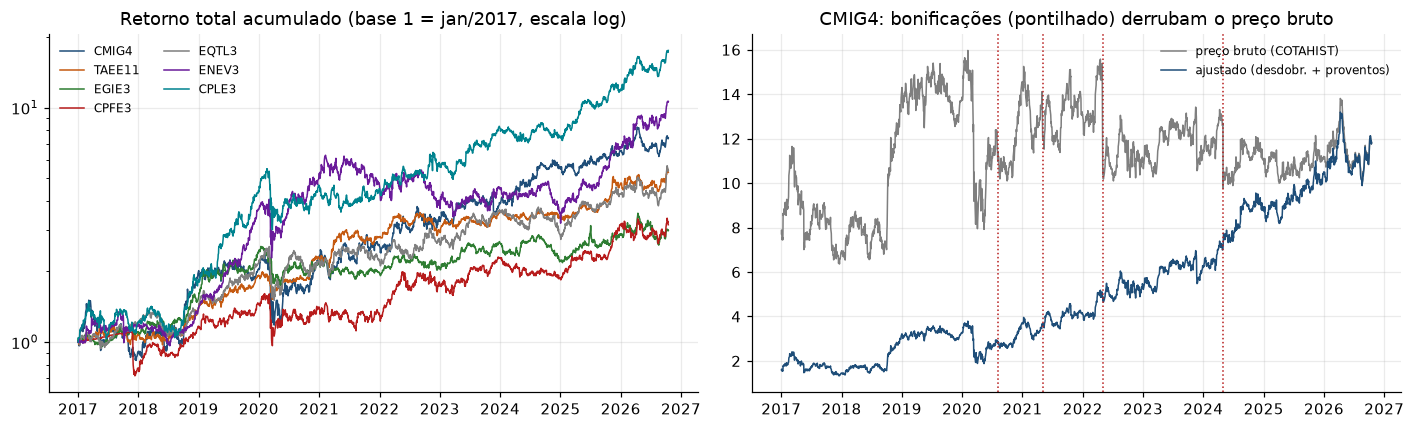

Retornos totais diários com |r| > 15% após o ajuste (devem ser eventos reais de mercado):
   ('CMIG4', datetime.date(2017, 5, 18), -0.229)
   ('CMIG4', datetime.date(2018, 10, 8), 0.164)
   ('CMIG4', datetime.date(2020, 3, 12), -0.215)
   ('CPFE3', datetime.date(2017, 11, 30), -0.186)
   ('ENEV3', datetime.date(2020, 3, 12), -0.186)
   ('ENEV3', datetime.date(2020, 3, 18), -0.215)
   ('CPLE3', datetime.date(2020, 3, 12), -0.155)
   ('CPLE3', datetime.date(2020, 3, 18), -0.155)
   ('CPLE3', datetime.date(2022, 11, 21), 0.18)


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cores = [AZUL, LARANJA, VERDE, VERMELHO, CINZA, ROXO, "#00838f"]
for (tk, s), c in zip(SERIES.items(), cores):
    ax[0].plot(s.index, s.S / s.S.iloc[0], color=c, lw=1, label=tk)
ax[0].set_yscale("log"); ax[0].set_title("Retorno total acumulado (base 1 = jan/2017, escala log)"); ax[0].legend(fontsize=8, ncol=2)

s = SERIES["CMIG4"]
ax[1].plot(s.index, s.S_bruto, color=CINZA, lw=1, label="preço bruto (COTAHIST)")
ax[1].plot(s.index, s.S, color=AZUL, lw=1, label="ajustado (desdobr. + proventos)")
for d in s.index[s.split]:
    ax[1].axvline(d, color=VERMELHO, ls=":", lw=1)
ax[1].set_title("CMIG4: bonificações (pontilhado) derrubam o preço bruto"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# checagem: o que sobrou de movimentos diários > 15% depois do ajuste
grandes = [(tk, d.date(), round(v, 3)) for tk, s in SERIES.items() for d, v in s.r[s.r.abs() > 0.15].items()]
print("Retornos totais diários com |r| > 15% após o ajuste (devem ser eventos reais de mercado):")
for g in grandes:
    print("  ", g)

**O que observar.**

* Todas as bonificações e desdobramentos do período foram localizados no pregão certo da B3 (coluna `ret_bruto_no_dia` ≈ $-\ln f$). No gráfico da direita, cada degrau do preço bruto da CMIG4 é uma bonificação, não uma perda.
* Os movimentos de mais de 15% que sobram depois do ajuste são **eventos reais**: o *Joesley Day* (18/05/2017, CMIG4 −23%), a OPA da CPFL (30/11/2017) e os *circuit breakers* da Covid (12 e 18/03/2020). Eles **devem** ficar nos dados: são exatamente as caudas que o VaR precisa prever.
* A coluna de proventos confirma o que se sabe do setor: as elétricas pagam muito (TAEE11 ≈ 10% a.a.). Usamos o **retorno total** para medir risco do acionista; para as opções (Parte 6) isso importa menos, porque a B3 **ajusta o strike** das opções pelos proventos.

---
# Parte 2 — Fatos estilizados: as premissas do MBG valem aqui?

Todo o notebook original supõe o **movimento browniano geométrico** (MBG): log-retornos diários **normais**, **independentes** e com **volatilidade constante**. Antes de usar o modelo para prever risco, testamos cada premissa nos dados:

| Premissa do MBG | Teste | Se for falsa... |
|---|---|---|
| log-retornos normais | assimetria, curtose e Jarque–Bera; QQ-plot | as caudas (VaR 99%) ficam subestimadas |
| independência | Ljung–Box nos retornos | o drift seria previsível (pouco relevante para risco) |
| $\sigma$ constante | Ljung–Box nos retornos **ao quadrado**; volatilidade móvel | o risco muda com o tempo: o VaR precisa reagir (EWMA/GARCH) |

O teste de Ljung–Box soma as autocorrelações ao quadrado até a defasagem $m$: $Q=n(n+2)\sum_{k=1}^m\hat\rho_k^2/(n-k)\sim\chi^2_m$ sob independência.

In [5]:
pd.options.display.width = 220
pd.options.display.max_columns = 30

def ljung_box(x, defasagens=10):
    x = np.asarray(x) - np.mean(x)
    n, den = len(x), np.sum(x * x)
    rho = np.array([np.sum(x[k:] * x[:-k]) / den for k in range(1, defasagens + 1)])
    Q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, defasagens + 1)))
    return Q, stats.chi2.sf(Q, defasagens)

linhas = {}
for tk, s in SERIES.items():
    r = s.r.dropna().values
    z = (r - r.mean()) / r.std()
    linhas[tk] = {
        "vol. anual": r.std() * np.sqrt(DU),
        "assimetria": stats.skew(r),
        "curtose": stats.kurtosis(r, fisher=False),
        "p Jarque-Bera": stats.jarque_bera(r).pvalue,
        "p Ljung-Box r": ljung_box(r)[1],
        "p Ljung-Box r²": ljung_box(r**2)[1],
        "ρ₁(r)": np.corrcoef(r[1:], r[:-1])[0, 1],
        "ρ₁(r²)": np.corrcoef(r[1:]**2, r[:-1]**2)[0, 1],
        "% dias |z|>3": 100 * np.mean(np.abs(z) > 3),
        "% teórico normal": 100 * 2 * norm.sf(3),
    }
fatos = pd.DataFrame(linhas).T
display(fatos)

,vol. anual,assimetria,curtose,p Jarque-Bera,p Ljung-Box r,p Ljung-Box r²,ρ₁(r),ρ₁(r²),% dias |z|>3,% teórico normal
CMIG4,0.3555,-0.6145,14.6103,0.0000,0.0011,0.0000,-0.0273,0.2629,1.2341,0.2700
TAEE11,0.2005,-0.0025,5.5337,0.0000,0.0069,0.0000,-0.0482,0.1300,0.9872,0.2700
EGIE3,0.2289,-0.0340,7.0325,0.0000,0.0000,0.0000,-0.1021,0.4133,1.8100,0.2700
CPFE3,0.2627,-1.1360,16.5617,0.0000,0.0000,0.0000,-0.0159,0.2413,1.2341,0.2700
EQTL3,0.2708,-0.0289,7.7736,0.0000,0.0002,0.0000,-0.0667,0.2031,1.1929,0.2700
ENEV3,0.3374,-0.5165,14.1291,0.0000,0.0000,0.0000,-0.1009,0.2097,1.1107,0.2700
CPLE3,0.3138,-0.1135,11.9987,0.0000,0.0002,0.0000,-0.0580,0.2315,1.1929,0.2700


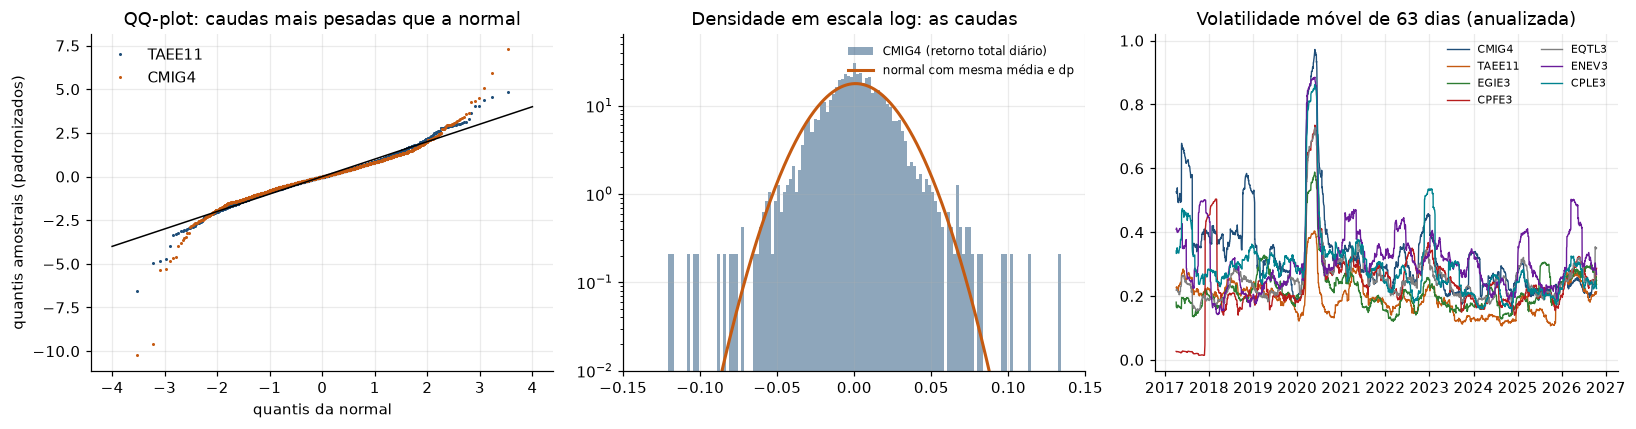

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for tk, c in [("TAEE11", AZUL), ("CMIG4", LARANJA)]:
    r = SERIES[tk].r.dropna()
    z = np.sort(((r - r.mean()) / r.std()).values)
    q = norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
    ax[0].plot(q, z, ".", ms=2, color=c, label=tk)
ax[0].plot([-4, 4], [-4, 4], color="k", lw=1)
ax[0].set_xlabel("quantis da normal"); ax[0].set_ylabel("quantis amostrais (padronizados)")
ax[0].set_title("QQ-plot: caudas mais pesadas que a normal"); ax[0].legend()

r = SERIES["CMIG4"].r.dropna()
x = np.linspace(-0.12, 0.12, 400)
ax[1].hist(r, bins=200, density=True, color=AZUL, alpha=0.5, label="CMIG4 (retorno total diário)")
ax[1].plot(x, norm.pdf(x, r.mean(), r.std()), color=LARANJA, lw=2, label="normal com mesma média e dp")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-2, None); ax[1].set_xlim(-0.15, 0.15)
ax[1].set_title("Densidade em escala log: as caudas"); ax[1].legend(fontsize=8)

for (tk, s), c in zip(SERIES.items(), cores):
    ax[2].plot(s.index, s.r.rolling(63).std() * np.sqrt(DU), color=c, lw=0.9, label=tk)
ax[2].set_title("Volatilidade móvel de 63 dias (anualizada)"); ax[2].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**O que observar.**

* **Normalidade é rejeitada em todas as ações** (p-valor de Jarque–Bera ≈ 0): a curtose vai de 5,5 (TAEE11) a 16,6 (CPFE3), contra 3 da normal, e dias com $|z|>3$ acontecem 4 a 7 vezes mais do que a normal prevê (1–1,8% contra 0,27%). No QQ-plot os pontos fogem da reta justamente nas caudas, onde vivem o VaR e o ES.
* **A volatilidade não é constante** (Ljung–Box em $r^2$ com p-valor ≈ 0): ela vem em *clusters*. O gráfico da direita mostra que todas as elétricas multiplicaram a volatilidade juntas em março de 2020 e depois voltaram.
* O Ljung–Box também rejeita a independência dos próprios retornos, mas compare as colunas $\rho_1$: a dependência entre os **tamanhos** dos movimentos ($r^2$) é bem mais forte do que entre as **direções** ($r$). Prever a direção é difícil; prever a turbulência, não. Essa é a justificativa empírica para os modelos EWMA e GARCH da próxima parte.
* **Consequência para o notebook original:** o MBG com $\sigma$ constante é ótimo para *explicar* a teoria, mas os testes acima já indicam que ele deve **subestimar o risco de cauda** e **reagir devagar** a crises. A Parte 4 mede o tamanho desse erro.

---
# Parte 3 — Os modelos concorrentes

Comparamos cinco modelos para a distribuição do log-retorno do dia seguinte, $r_{t+1}\mid\mathcal F_t$. Todos são **reestimados a cada data só com o passado**.

| Modelo | Distribuição de $r_{t+1}$ | Calibração com dados até $t$ | Papel no estudo |
|---|---|---|---|
| **MBG** | $\mathcal N(\hat\mu,\hat\sigma^2)$ | média e dp dos últimos 252 dias | o modelo do notebook original (Partes 1–5) |
| **EWMA** (RiskMetrics) | $\mathcal N(0,\sigma^2_{t+1})$, $\sigma^2_{t+1}=\lambda\sigma^2_t+(1-\lambda)r_t^2$ | $\lambda=0{,}94$ fixo | MBG com $\sigma$ que reage a choques |
| **GARCH(1,1)-t** | $\mu+\sigma_{t+1}\,\varepsilon$, $\varepsilon\sim t_\nu$ padronizada, $\sigma^2_{t+1}=\omega+\alpha\epsilon_t^2+\beta\sigma_t^2$ | máxima verossimilhança (`fit_garch_t` do app), janela de até 1000 dias, reestimado a cada 10 pregões | o modelo usado pelo app (`pricing/garch_montecarlo.py`) |
| **Simulação histórica (HS)** | distribuição empírica dos últimos 500 retornos | nenhuma | benchmark não paramétrico dos bancos |
| **HS filtrada (FHS)** | $\mu+\sigma_{t+1}\,\hat z$, $\hat z$ = resíduos padronizados do GARCH | GARCH + resíduos empíricos | GARCH sem impor a forma da cauda |

**Como cada modelo vira VaR e ES** (perda $L=-r$, nível $\alpha$, $p=1-\alpha$):

* Normal: $\mathrm{VaR}=-(\mu+\sigma z_p)$ e $\mathrm{ES}=-\mu+\sigma\,\varphi(z_p)/p$.
* $t_\nu$ padronizada (fator $s=\sqrt{(\nu-2)/\nu}$): $\mathrm{VaR}=-(\mu+\sigma s\,t_p)$ e $\mathrm{ES}=-\mu+\sigma s\,\frac{\nu+t_p^2}{\nu-1}\frac{f_\nu(t_p)}{p}$.
* HS/FHS: quantil empírico e média da cauda, como a função `var_es` do original.

Para 1 dia não é preciso simular: as fórmulas são exatas. **Para 10 dias o GARCH não tem fórmula fechada** (a volatilidade muda ao longo do caminho e a soma de $t$'s não é $t$), e aí entra o Monte Carlo (Seção 4.4).

In [7]:
def filtro_garch(r, g, v0):
    """Variâncias condicionais do GARCH (mesma recursão de fit_garch_t) para a série r.
    Devolve sig2[i] = variância prevista para r[i] com informação até i-1 (len(r)+1 valores).
    v0 = variância inicial, calculada só com a janela de treino (sem olhar o futuro)."""
    choque = r - g.mean_daily_return
    drivers = g.omega + g.alpha * np.concatenate([[v0], choque**2])
    sig2, _ = signal.lfilter([1.0], [1.0, -g.beta], drivers, zi=[g.beta * v0])
    return np.maximum(sig2, 1e-10)

def previsoes_1d(s):
    """Para cada pregão t (a partir de JANELA_TREINO) prevê a distribuição de r_{t+1} pelos 5 modelos.
    Guarda tudo o que as partes seguintes reaproveitam (parâmetros do GARCH, resíduos, sigma)."""
    r = s.r.values
    n = len(r)
    idx_ini = JANELA_TREINO
    out = {k: np.full(n, np.nan) for k in ["mu_mbg", "sig_mbg", "sig_ewma", "mu_g", "sig_g", "nu_g", "omega", "alpha", "beta"]}
    # EWMA (recursão causal, inicializada com a variância dos 30 primeiros dias)
    lam, v = 0.94, np.nanvar(r[1:31])
    for i in range(1, n):
        out["sig_ewma"][i] = np.sqrt(v)          # previsão para r[i] feita em i-1
        v = lam * v + (1 - lam) * r[i]**2
    sig_ewma_prox = np.r_[out["sig_ewma"][1:], np.sqrt(v)]  # previsão para i+1 feita em i
    out["sig_ewma"] = sig_ewma_prox
    residuos = {}
    g = None
    for t in range(idx_ini, n):
        hist = r[max(1, t - 251):t + 1]
        out["mu_mbg"][t], out["sig_mbg"][t] = hist.mean(), hist.std(ddof=1)
        if (t - idx_ini) % REFIT_GARCH == 0:     # reestima o GARCH (só com o passado)
            ini_jan = max(1, t + 1 - JANELA_GARCH)
            jan = r[ini_jan:t + 1]
            g = fit_garch_t(jan)
            bloco_fim = min(n, t + REFIT_GARCH)
            # filtra da janela até o fim do bloco com os parâmetros fixos: a variância
            # prevista para r[i] só usa r até i-1, então não há olhar para o futuro
            sig2 = filtro_garch(r[ini_jan:bloco_fim], g, v0=(jan - g.mean_daily_return).var())
            residuos[t] = (jan - g.mean_daily_return) / np.sqrt(sig2[:len(jan)])
        out["sig_g"][t] = np.sqrt(sig2[t + 1 - ini_jan])     # previsão para r[t+1] feita em t
        out["mu_g"][t], out["nu_g"][t] = g.mean_daily_return, g.degrees_of_freedom
        out["omega"][t], out["alpha"][t], out["beta"][t] = g.omega, g.alpha, g.beta
    prev = pd.DataFrame(out, index=s.index)
    return prev, residuos

t0 = time.time()
PREV, RESID = {}, {}
for tk, s in SERIES.items():
    PREV[tk], RESID[tk] = previsoes_1d(s)
print(f"previsões geradas em {time.time() - t0:.0f} s")

# checagem: a volatilidade do GARCH do último dia deve bater com fit_garch_t na janela final
tk = "CMIG4"; s = SERIES[tk]; t = len(s) - 1
g_final = fit_garch_t(s.r.values[t + 1 - JANELA_GARCH:t + 1])
print(f"{tk}: σ GARCH próxima (refeito agora) = {g_final.current_annual_volatility:.2%}   "
      f"σ GARCH no backtest (filtrado desde o último refit) = {PREV[tk].sig_g.iloc[-1] * np.sqrt(DU):.2%}")

previsões geradas em 29 s
CMIG4: σ GARCH próxima (refeito agora) = 24.16%   σ GARCH no backtest (filtrado desde o último refit) = 24.19%


,σ MBG (252d),σ EWMA,σ GARCH (amanhã),σ GARCH longo prazo,α,β,persistência α+β,ν (graus de liberdade),meia-vida do choque (dias)
CMIG4,0.2387,0.2571,0.2419,0.2509,0.0834,0.8229,0.9063,8.1484,7.0468
TAEE11,0.2328,0.2375,0.2280,0.1854,0.0504,0.9380,0.9884,6.8091,59.1725
EGIE3,0.2663,0.2449,0.2307,0.2163,0.0501,0.9197,0.9697,6.6167,22.5404
CPFE3,0.2676,0.3265,0.3203,0.2421,0.1080,0.8137,0.9217,6.2460,8.5052
EQTL3,0.2888,0.4620,0.3741,0.2448,0.0453,0.8963,0.9417,7.1073,11.5332
ENEV3,0.3490,0.2787,0.2750,0.3005,0.0785,0.8541,0.9326,9.8381,9.9314
CPLE3,0.2571,0.2195,0.2289,0.2421,0.0494,0.8988,0.9482,8.0652,13.0383


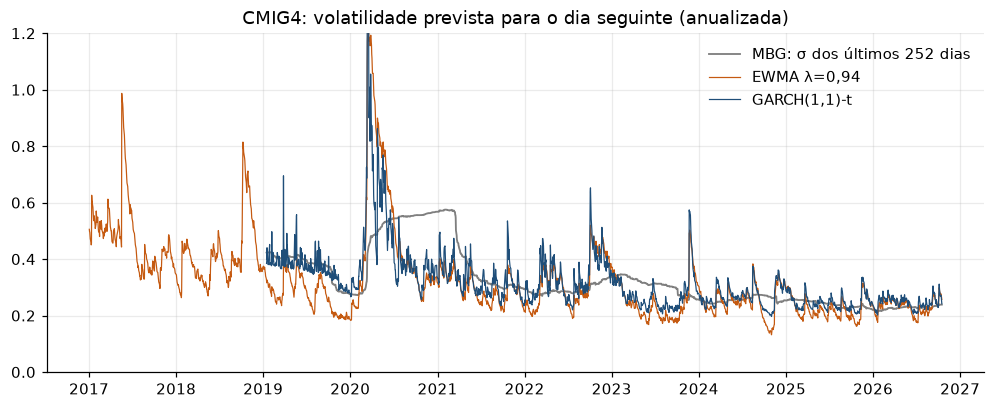

In [8]:
# fotografia dos parâmetros na última data disponível
foto = {}
for tk in TICKERS:
    p = PREV[tk].iloc[-1]
    foto[tk] = {"σ MBG (252d)": p.sig_mbg * np.sqrt(DU), "σ EWMA": p.sig_ewma * np.sqrt(DU),
                "σ GARCH (amanhã)": p.sig_g * np.sqrt(DU),
                "σ GARCH longo prazo": np.sqrt(p.omega / (1 - p.alpha - p.beta) * DU),
                "α": p.alpha, "β": p.beta, "persistência α+β": p.alpha + p.beta, "ν (graus de liberdade)": p.nu_g,
                "meia-vida do choque (dias)": np.log(0.5) / np.log(p.alpha + p.beta)}
display(pd.DataFrame(foto).T)

fig, ax = plt.subplots(figsize=(11, 4))
p = PREV["CMIG4"]
ax.plot(p.index, p.sig_mbg * np.sqrt(DU), color=CINZA, lw=1.2, label="MBG: σ dos últimos 252 dias")
ax.plot(p.index, p.sig_ewma * np.sqrt(DU), color=LARANJA, lw=0.8, label="EWMA λ=0,94")
ax.plot(p.index, p.sig_g * np.sqrt(DU), color=AZUL, lw=0.8, label="GARCH(1,1)-t")
ax.set_ylim(0, 1.2); ax.set_title("CMIG4: volatilidade prevista para o dia seguinte (anualizada)"); ax.legend()
plt.show()

**O que observar.**

* A **persistência** $\alpha+\beta$ do GARCH vai de 0,91 (CMIG4) a 0,99 (TAEE11): um choque de volatilidade leva de uma semana a três meses para se dissipar pela metade (coluna "meia-vida"). Os graus de liberdade $\nu$ entre 6 e 10 indicam caudas condicionais mais pesadas que a normal ($\nu=\infty$). Note que parte da curtose da Parte 2 já é explicada pela volatilidade variável: a $t$ condicional precisa de cauda menos extrema que a distribuição incondicional.
* No gráfico, a volatilidade do MBG (janela de 252 dias) **demora meses** para subir em 2020 e **continua alta** um ano depois de a crise passar. EWMA e GARCH sobem em dias e voltam em semanas. Em termos de risco: o MBG chega **atrasado** na crise e fica **conservador demais** depois dela.

---
# Parte 4 — Backtest de risco: o VaR e o ES previstos funcionam?

Na Parte 4 do original, o VaR era conferido contra a fórmula lognormal exata. Com dados reais **não existe resposta exata**: o único teste possível é o **backtest** — prever o VaR de cada dia e contar quantas vezes a perda real o ultrapassou (uma **violação**).

Se o modelo está correto, as violações $I_t=\mathbf 1\{L_t>\mathrm{VaR}_t\}$ devem ser

1. **na frequência certa**: $\mathbb P(I_t=1)=p$ (1% para o VaR 99%) — teste de **Kupiec** (POF);
2. **independentes**: uma violação hoje não deve tornar outra amanhã mais provável — teste de **Christoffersen**. Violações em sequência significam que o modelo demora a reagir a crises;
3. e o **ES** deve acertar o **tamanho médio** da perda quando o VaR é violado — teste $Z_2$ de **Acerbi–Székely**.

**Estatísticas.** Com $n$ dias e $x$ violações, $\hat p=x/n$:

$$
LR_{\text{POF}}=-2\ln\frac{(1-p)^{n-x}p^x}{(1-\hat p)^{n-x}\hat p^x}\sim\chi^2_1,\qquad
LR_{\text{ind}}=-2\ln\frac{(1-\hat\pi)^{n_{00}+n_{10}}\hat\pi^{n_{01}+n_{11}}}{(1-\hat\pi_0)^{n_{00}}\hat\pi_0^{n_{01}}(1-\hat\pi_1)^{n_{10}}\hat\pi_1^{n_{11}}}\sim\chi^2_1,
$$

onde $n_{ij}$ conta as transições de $I_{t-1}=i$ para $I_t=j$ e $LR_{\text{cc}}=LR_{\text{POF}}+LR_{\text{ind}}\sim\chi^2_2$ (cobertura condicional). Para o ES a 97,5% (padrão FRTB/Basileia):

$$
Z_2=1-\frac{1}{n\,p}\sum_t\frac{L_t\,I_t}{\mathrm{ES}_t},\qquad \mathbb E[Z_2]=0 \text{ se o ES estiver certo};
$$

$Z_2<0$ significa ES **subestimado**. Acerbi e Székely (2014) dão os limites aproximados $-0{,}70$ (5% de significância) e $-1{,}8$ (0,01%).

**Para ordenar os modelos** (e não só aprovar/reprovar) usamos a função de perda **FZ0** de Fissler–Ziegel/Patton, que avalia VaR e ES **juntos** e é mínima, em média, no modelo verdadeiro. A diferença de FZ0 contra o MBG é testada com Diebold–Mariano (erro-padrão HAC).

## 4.1 Montando o backtest

Para cada ação e cada pregão $t$ do período de teste (jan/2019 em diante, depois de 500 dias de treino), cada modelo produz $\mathrm{VaR}_t$ e $\mathrm{ES}_t$ para a perda de $t+1$. A tabela `BT` guarda, lado a lado, a perda realizada em $t+1$ e as previsões feitas em $t$.

In [9]:
ALPHAS = [0.95, 0.975, 0.99]   # 95% e 99% para o VaR; 97,5% para o ES (padrão FRTB)

def var_es_modelo(prev, resid_por_refit, r_hist_por_t, modelo, alpha):
    """VaR e ES (em perda = -log-retorno) previstos para t+1, vetorizados nas datas."""
    p = 1 - alpha
    if modelo == "MBG":
        mu, sg = prev.mu_mbg.values, prev.sig_mbg.values
        return -(mu + sg * norm.ppf(p)), -mu + sg * norm.pdf(norm.ppf(p)) / p
    if modelo == "EWMA":
        sg = prev.sig_ewma.values
        return -(sg * norm.ppf(p)), sg * norm.pdf(norm.ppf(p)) / p
    if modelo == "GARCH-t":
        mu, sg, nu = prev.mu_g.values, prev.sig_g.values, prev.nu_g.values
        esc = np.sqrt((nu - 2) / nu)
        tp = stats.t.ppf(p, nu)
        es_pad = (nu + tp**2) / (nu - 1) * stats.t.pdf(tp, nu) / p
        return -(mu + sg * esc * tp), -mu + sg * esc * es_pad
    n = len(prev)
    var, es = np.full(n, np.nan), np.full(n, np.nan)
    if modelo == "HS":
        for t, h in r_hist_por_t.items():
            perdas = -h
            v = np.quantile(perdas, alpha); var[t], es[t] = v, perdas[perdas >= v].mean()
        return var, es
    if modelo == "FHS":
        refits = sorted(resid_por_refit)
        for t in range(len(prev)):
            if np.isnan(prev.sig_g.values[t]):
                continue
            ult = refits[np.searchsorted(refits, t, side="right") - 1]
            z = -resid_por_refit[ult]
            qz = np.quantile(z, alpha); ez = z[z >= qz].mean()
            mu, sg = prev.mu_g.values[t], prev.sig_g.values[t]
            var[t], es[t] = -mu + sg * qz, -mu + sg * ez
        return var, es
    raise ValueError(modelo)

MODELOS = ["MBG", "EWMA", "GARCH-t", "HS", "FHS"]
COR_MODELO = dict(zip(MODELOS, [CINZA, LARANJA, AZUL, VERDE, ROXO]))

# monta a tabela longa: uma linha por (ticker, data), com a perda realizada em t+1 e as previsões feitas em t
BT = {}
for tk, s in SERIES.items():
    r = s.r.values
    hist = {t: r[t - 499:t + 1] for t in range(JANELA_TREINO, len(r) - 1)}
    df = pd.DataFrame(index=s.index[:-1])
    df["perda"] = -r[1:]                    # perda realizada no dia seguinte
    for m in MODELOS:
        for a in ALPHAS:
            v, e = var_es_modelo(PREV[tk], RESID[tk], hist, m, a)
            df[f"VaR{a}_{m}"], df[f"ES{a}_{m}"] = v[:-1], e[:-1]
    BT[tk] = df.iloc[JANELA_TREINO:].dropna()
print("período do backtest:", BT["CMIG4"].index[0].date(), "a", BT["CMIG4"].index[-1].date(),
      f"({len(BT['CMIG4'])} dias por ação, {sum(len(d) for d in BT.values())} no total)")

período do backtest: 2019-01-15 a 2026-10-15 (1931 dias por ação, 13517 no total)


## 4.2 Resultados: frequência, independência e tamanho das violações

In [10]:
def kupiec(I, p):
    n, x = len(I), int(np.sum(I))
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = ((n - x) * np.log(1 - ph) if x < n else 0.0) + (x * np.log(ph) if x > 0 else 0.0)
    LR = -2 * (ll0 - ll1)
    return LR, stats.chi2.sf(LR, 1)

def christoffersen(I):
    I = np.asarray(I, dtype=int)
    a, b = I[:-1], I[1:]
    n00, n01 = np.sum((a == 0) & (b == 0)), np.sum((a == 0) & (b == 1))
    n10, n11 = np.sum((a == 1) & (b == 0)), np.sum((a == 1) & (b == 1))
    def ll(n_0, n_1):
        q = n_1 / (n_0 + n_1) if (n_0 + n_1) > 0 else 0
        return (n_0 * np.log(1 - q) if n_0 else 0) + (n_1 * np.log(q) if n_1 else 0)
    LR = -2 * (ll(n00 + n10, n01 + n11) - (ll(n00, n01) + ll(n10, n11)))
    return LR, stats.chi2.sf(LR, 1), (n11 / (n10 + n11) if (n10 + n11) else np.nan)

def z2_acerbi(perda, var, es, alpha=0.975):
    I = perda > var
    return 1 - np.sum(perda * I / es) / (len(perda) * (1 - alpha))

def fz0(perda, var, es, alpha):
    """Perda FZ0 (Patton, Ziegel & Chen 2019) em termos de retorno y=-perda; menor = melhor."""
    y, v, e = -perda, -var, -es
    p = 1 - alpha
    return -1 / (p * e) * (y <= v) * (v - y) + v / e + np.log(-e) - 1

def diebold_mariano(d, lags=5):
    d = np.asarray(d); n = len(d); dm = d - d.mean()
    gamma = [np.sum(dm[k:] * dm[:n - k]) / n for k in range(lags + 1)]
    var = gamma[0] + 2 * sum((1 - k / (lags + 1)) * gamma[k] for k in range(1, lags + 1))
    stat = d.mean() / np.sqrt(var / n)
    return stat, 2 * norm.sf(abs(stat))

linhas = []
for tk, df in BT.items():
    for m in MODELOS:
        for a in [0.95, 0.99]:
            I = (df.perda > df[f"VaR{a}_{m}"]).values
            LRp, p_pof = kupiec(I, 1 - a)
            LRi, p_ind, pi11 = christoffersen(I)
            linhas.append(dict(ticker=tk, modelo=m, nivel=f"VaR {a:.0%}", n=len(I), violações=int(I.sum()),
                               taxa=I.mean(), esperado=1 - a, p_kupiec=p_pof, p_indep=p_ind,
                               p_cc=stats.chi2.sf(LRp + LRi, 2), P_viol_apos_viol=pi11))
        a = 0.975
        z2 = z2_acerbi(df.perda.values, df[f"VaR{a}_{m}"].values, df[f"ES{a}_{m}"].values)
        linhas.append(dict(ticker=tk, modelo=m, nivel="ES 97,5%", n=len(df), z2=z2))
tab_bt = pd.DataFrame(linhas)

# visão agregada: taxa de violação (todas as ações juntas) e quantas ações passam em cada teste a 5%
tv = tab_bt[tab_bt.nivel != "ES 97,5%"]
resumo_var = pd.concat({
    nivel: pd.DataFrame({
        "taxa de violação": g.groupby("modelo").violações.sum() / g.groupby("modelo").n.sum(),
        "passa Kupiec (de 7)": g.groupby("modelo").p_kupiec.apply(lambda x: int((x > 0.05).sum())),
        "passa independência": g.groupby("modelo").p_indep.apply(lambda x: int((x > 0.05).sum())),
        "passa cobertura cond.": g.groupby("modelo").p_cc.apply(lambda x: int((x > 0.05).sum())),
    }).reindex(MODELOS)
    for nivel, g in tv.groupby("nivel")}, axis=1)
display(resumo_var.style.format("{:.2%}", subset=[c for c in resumo_var.columns if c[1] == "taxa de violação"]))
display(tab_bt[tab_bt.nivel == "ES 97,5%"].pivot(index="ticker", columns="modelo", values="z2")[MODELOS]
        .style.format("{:+.2f}").map(lambda v: "color: #b71c1c; font-weight: bold" if v < -0.70 else ""))

modelo,MBG,EWMA,GARCH-t,HS,FHS
ticker,,,,,
CMIG4,-0.27,-0.14,+0.32,+0.10,+0.18
CPFE3,-0.57,-0.25,-0.15,-0.31,+0.00
CPLE3,-0.32,-0.02,+0.22,-0.10,+0.11
EGIE3,-0.54,-0.40,-0.19,-0.46,-0.31
ENEV3,-0.17,-0.17,+0.11,-0.10,-0.07
EQTL3,-0.26,-0.05,+0.04,-0.40,-0.21
TAEE11,-0.38,-0.17,+0.12,-0.13,+0.14


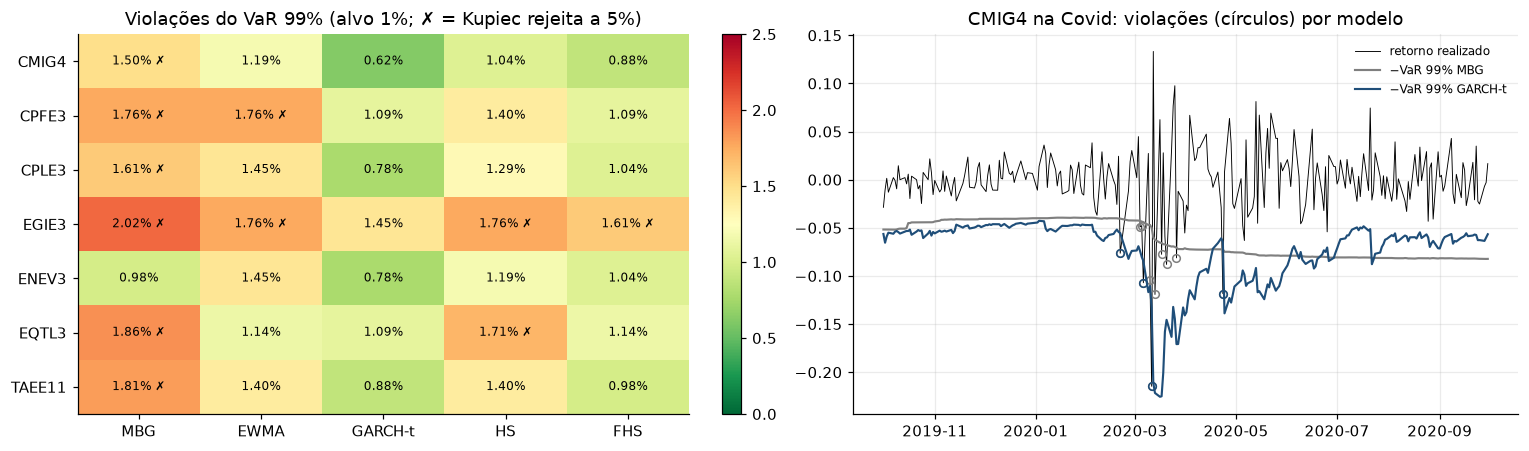

In [11]:
# taxa de violação do VaR 99% por ação e modelo (o alvo é 1%)
piv = tab_bt[tab_bt.nivel == "VaR 99%"].pivot(index="ticker", columns="modelo", values="taxa")[MODELOS] * 100
pk = tab_bt[tab_bt.nivel == "VaR 99%"].pivot(index="ticker", columns="modelo", values="p_kupiec")[MODELOS]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax[0].imshow(piv.values, cmap="RdYlGn_r", vmin=0, vmax=2.5, aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax[0].text(j, i, f"{piv.values[i, j]:.2f}%" + ("" if pk.values[i, j] > 0.05 else " ✗"),
                   ha="center", va="center", fontsize=8)
ax[0].set_xticks(range(len(MODELOS)), MODELOS); ax[0].set_yticks(range(len(piv)), piv.index)
ax[0].set_title("Violações do VaR 99% (alvo 1%; ✗ = Kupiec rejeita a 5%)"); ax[0].grid(False)
plt.colorbar(im, ax=ax[0], fraction=0.03)

df = BT["CMIG4"]
jan = df.loc["2019-10-01":"2020-09-30"]
ax[1].plot(jan.index, -jan.perda, color="k", lw=0.6, label="retorno realizado")
for m in ["MBG", "GARCH-t"]:
    ax[1].plot(jan.index, -jan[f"VaR0.99_{m}"], color=COR_MODELO[m], lw=1.4, label=f"−VaR 99% {m}")
    viol = jan[jan.perda > jan[f"VaR0.99_{m}"]]
    ax[1].plot(viol.index, -viol.perda, "o", ms=5, mfc="none", color=COR_MODELO[m])
ax[1].set_title("CMIG4 na Covid: violações (círculos) por modelo"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.3 Semáforo de Basileia e ranking dos modelos

In [12]:
# semáforo de Basileia: em cada janela móvel de 250 dias, quantas violações do VaR 99%?
# verde ≤ 4, amarelo 5–9, vermelho ≥ 10 (Basel Committee, 1996)
semaforo = {}
for m in MODELOS:
    zonas = []
    for tk, df in BT.items():
        I = (df.perda > df[f"VaR0.99_{m}"]).astype(int)
        cont = I.rolling(250).sum().dropna().iloc[::21]          # uma janela por mês
        zonas.append(pd.cut(cont, [-1, 4, 9, 1e9], labels=["verde", "amarelo", "vermelho"]))
    z = pd.concat(zonas)
    semaforo[m] = z.value_counts(normalize=True).reindex(["verde", "amarelo", "vermelho"]) * 100
semaforo = pd.DataFrame(semaforo).T
display(semaforo.style.format("{:.0f}%").set_caption("% das janelas de 250 dias em cada zona (todas as ações)"))

# ranking pela perda FZ0 (VaR+ES 97,5%) e teste de Diebold–Mariano contra o MBG
a = 0.975
rank = {}
for m in MODELOS:
    fz = {tk: fz0(df.perda.values, df[f"VaR{a}_{m}"].values, df[f"ES{a}_{m}"].values, a) for tk, df in BT.items()}
    rank[m] = fz
fz_tab = pd.DataFrame({m: {tk: v.mean() for tk, v in rank[m].items()} for m in MODELOS})
dm = pd.DataFrame({m: {tk: diebold_mariano(rank[m][tk] - rank["MBG"][tk])[1] for tk in BT} for m in MODELOS if m != "MBG"})
fz_tab.loc["média"] = fz_tab.mean()
display(fz_tab.style.format("{:.4f}").highlight_min(axis=1, color="#c8e6c9")
        .set_caption("Perda FZ0 média (menor = melhor). Verde = melhor modelo da linha."))
display(dm.style.format("{:.3f}").map(lambda v: "font-weight: bold" if v < 0.05 else "")
        .set_caption("p-valor de Diebold–Mariano: modelo vs MBG (negrito = diferença significativa a 5%)"))

,verde,amarelo,vermelho
MBG,62%,28%,10%
EWMA,66%,34%,0%
GARCH-t,90%,10%,0%
HS,68%,25%,7%
FHS,82%,18%,0%


,MBG,EWMA,GARCH-t,HS,FHS
CMIG4,-2.8309,-3.0729,-3.0590,-2.8656,-3.0758
TAEE11,-3.3879,-3.5162,-3.5274,-3.4087,-3.5197
EGIE3,-3.1380,-3.2960,-3.3000,-3.1041,-3.2822
CPFE3,-2.9673,-3.1375,-3.1398,-2.9228,-3.1292
EQTL3,-3.0061,-3.2226,-3.2186,-2.9723,-3.2156
ENEV3,-2.7940,-2.9437,-2.9571,-2.7815,-2.9405
CPLE3,-2.9327,-3.1093,-3.1043,-2.9304,-3.1090
média,-3.0081,-3.1855,-3.1866,-2.9979,-3.1817


,EWMA,GARCH-t,HS,FHS
CMIG4,0.017,0.044,0.392,0.027
TAEE11,0.050,0.012,0.352,0.019
EGIE3,0.038,0.021,0.112,0.036
CPFE3,0.169,0.246,0.077,0.272
EQTL3,0.025,0.023,0.017,0.024
ENEV3,0.225,0.239,0.594,0.260
CPLE3,0.074,0.072,0.921,0.060


**O que observar.**

* **O MBG do notebook original falha no VaR 99%.** Ele é violado em 1,65% dos dias (65% a mais do que promete); o teste de Kupiec o rejeita em 6 das 7 ações e a cobertura condicional em 7 de 7. No gráfico da Covid, a linha cinza quase não se mexe enquanto as perdas explodem: as violações vêm **em sequência**, e é isso que o teste de independência detecta. No semáforo de Basileia, ~10% das janelas anuais do MBG caem na zona **vermelha** (que, num banco, aumenta o capital exigido).
* No VaR 95% o MBG erra para o **outro lado** (4,4% de violações, menos que 5%). Essa é a assinatura das caudas pesadas: uma normal com o mesmo desvio-padrão é larga demais no "miolo" e estreita demais na cauda. Por isso testar só o VaR 95% daria a falsa impressão de que o MBG é conservador.
* **O GARCH-t (o modelo do app) passa em tudo:** 0,95% de violações a 99%, aprovado nos três testes nas 7 ações, nenhuma janela vermelha e 90% das janelas verdes. A FHS vem logo atrás. O EWMA reage rápido, mas, por usar a normal, ainda viola demais a 99% (1,45%). A HS reage devagar (janela de 500 dias) e gera violações agrupadas.
* **ES.** Nenhum modelo tem $Z_2<-0{,}70$, então o teste de Acerbi–Székely não rejeita nenhum a 5%. Mas o **sinal** é informativo: o $Z_2$ do MBG é negativo nas 7 ações (o ES é sistematicamente subestimado), enquanto o do GARCH-t é positivo em 5 de 7.
* **Ranking (FZ0).** GARCH-t, EWMA e FHS praticamente empatam no topo; MBG e HS ficam atrás. A vantagem do GARCH-t sobre o MBG é estatisticamente significativa (Diebold–Mariano, 5%) em 4 das 7 ações (CMIG4, TAEE11, EGIE3, EQTL3). Em CPFE3, ENEV3 e CPLE3 ela existe, mas não é significativa.
* A **EGIE3** é a ação mais difícil: só o GARCH-t não é rejeitado nela.

## 4.4 Horizonte de 10 dias: aqui o Monte Carlo é indispensável

O padrão regulatório é o VaR de **10 dias** (o `HORIZ` do notebook original). Há dois jeitos de obtê-lo:

* **regra da raiz do tempo**: $\mathrm{VaR}_{10}=\sqrt{10}\,\mathrm{VaR}_1$. Ela é exata **só no MBG** (incrementos i.i.d. normais);
* **Monte Carlo do GARCH**: simular 10 dias em que a volatilidade **evolui** com os choques sorteados e a cauda $t$ se agrega ao longo do caminho.

**Passo a passo do Monte Carlo GARCH-t** (em cada data $t$, $M=20\,000$ trajetórias):

1. partir de $\sigma^2_{t+1}$ e dos parâmetros $(\mu,\omega,\alpha,\beta,\nu)$ estimados até $t$;
2. para $k=1,\dots,10$: sortear $\varepsilon_k\sim t_\nu$ padronizada, $\epsilon_k=\sigma_k\varepsilon_k$, atualizar $\sigma^2_{k+1}=\omega+\alpha\epsilon_k^2+\beta\sigma_k^2$;
3. log-retorno em 10 dias: $\sum_k(\mu+\epsilon_k)$; VaR e ES saem dos quantis da amostra simulada (como na Seção 4.1 do original).

A FHS faz o mesmo sorteando $\varepsilon_k$ dos **resíduos históricos** em vez da $t$. Para que as violações sejam independentes, usamos janelas de 10 dias **sem sobreposição**.

In [13]:
def simular_garch(mu, omega, alpha, beta, nu, sig2_ini, h, M, g, residuos=None):
    """Log-preço acumulado (M, h) de trajetórias GARCH: inovação t_ν padronizada ou bootstrap de resíduos."""
    var = np.full(M, sig2_ini)
    acum = np.zeros((M, h))
    soma = np.zeros(M)
    esc = np.sqrt((nu - 2) / nu)
    for k in range(h):
        eps = g.choice(residuos, M) if residuos is not None else g.standard_t(nu, M) * esc
        choque = np.sqrt(var) * eps
        soma = soma + mu + choque
        acum[:, k] = soma
        var = omega + alpha * choque**2 + beta * var
    return acum

def var_es_amostra(perdas, alpha):
    v = np.quantile(perdas, alpha)
    return v, perdas[perdas >= v].mean()

H10, M10 = 10, 20_000
g10 = np.random.default_rng(SEMENTE + 10)
linhas10 = []
t0 = time.time()
for tk, s in SERIES.items():
    r, P = s.r.values, PREV[tk]
    refits = np.array(sorted(RESID[tk]))
    for t in range(JANELA_TREINO, len(r) - H10, H10):
        perda_real = -r[t + 1:t + 1 + H10].sum()
        p = P.iloc[t]
        lin = dict(ticker=tk, data=s.index[t], perda=perda_real)
        sims = {
            "GARCH-t (MC)": simular_garch(p.mu_g, p.omega, p.alpha, p.beta, p.nu_g, p.sig_g**2, H10, M10, g10)[:, -1],
            "FHS (MC)": simular_garch(p.mu_g, p.omega, p.alpha, p.beta, p.nu_g, p.sig_g**2, H10, M10, g10,
                                       residuos=RESID[tk][refits[refits <= t][-1]])[:, -1],
        }
        hist10 = np.convolve(r[t - 499:t + 1], np.ones(H10), "valid")      # somas móveis de 10 dias
        for a in [0.95, 0.99]:
            zp = norm.ppf(1 - a)
            lin[f"VaR{a}_MBG (√10)"] = -(H10 * p.mu_mbg + np.sqrt(H10) * p.sig_mbg * zp)
            lin[f"VaR{a}_EWMA (√10)"] = -(np.sqrt(H10) * p.sig_ewma * zp)
            esc = np.sqrt((p.nu_g - 2) / p.nu_g)
            lin[f"VaR{a}_GARCH-t (√10)"] = -(H10 * p.mu_g + np.sqrt(H10) * p.sig_g * esc * stats.t.ppf(1 - a, p.nu_g))
            lin[f"VaR{a}_HS (10d)"] = np.quantile(-hist10, a)
            for nome, x in sims.items():
                lin[f"VaR{a}_{nome}"] = np.quantile(-x, a)
        linhas10.append(lin)
BT10 = pd.DataFrame(linhas10)
print(f"Monte Carlo de 10 dias: {len(BT10)} janelas em {time.time() - t0:.0f} s")

MOD10 = ["MBG (√10)", "EWMA (√10)", "GARCH-t (√10)", "GARCH-t (MC)", "FHS (MC)", "HS (10d)"]
res10 = {}
for m in MOD10:
    lin = {}
    for a in [0.95, 0.99]:
        I = (BT10.perda > BT10[f"VaR{a}_{m}"]).values
        lin[f"taxa {a:.0%}"] = I.mean()
        lin[f"p Kupiec {a:.0%} (todas)"] = kupiec(I, 1 - a)[1]
        lin[f"ações que passam {a:.0%}"] = int(sum(kupiec((g.perda > g[f"VaR{a}_{m}"]).values, 1 - a)[1] > 0.05
                                               for _, g in BT10.groupby("ticker")))
    lin["VaR 99% médio"] = BT10[f"VaR0.99_{m}"].mean()
    res10[m] = lin
res10 = pd.DataFrame(res10).T
display(res10.style.format({c: "{:.2%}" for c in res10.columns if c.startswith("taxa") or c.startswith("VaR")} |
                           {c: "{:.3f}" for c in res10.columns if c.startswith("p ")}))

Monte Carlo de 10 dias: 1351 janelas em 10 s


,taxa 95%,p Kupiec 95% (todas),ações que passam 95%,taxa 99%,p Kupiec 99% (todas),ações que passam 99%,VaR 99% médio
MBG (√10),3.40%,0.004,7.000000,1.11%,0.689,7.000000,11.81%
EWMA (√10),2.66%,0.000,4.000000,0.89%,0.674,5.000000,12.04%
GARCH-t (√10),3.63%,0.015,6.000000,0.67%,0.189,5.000000,12.81%
GARCH-t (MC),3.33%,0.003,6.000000,0.74%,0.314,5.000000,12.82%
FHS (MC),3.33%,0.003,5.000000,0.67%,0.189,4.000000,13.33%
HS (10d),4.52%,0.406,7.000000,1.33%,0.243,7.000000,14.92%


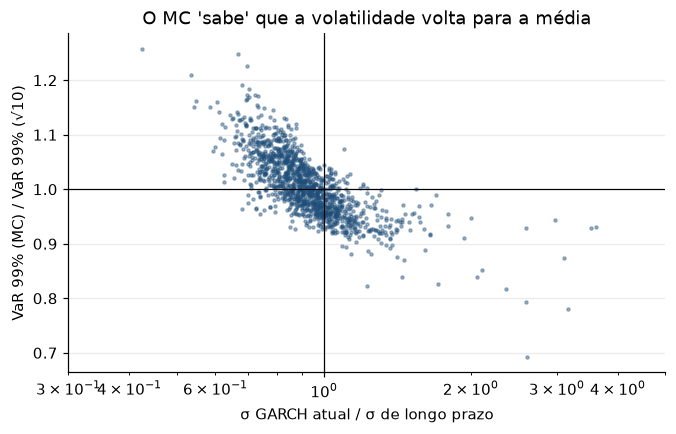

In [14]:
# Onde √10 e Monte Carlo divergem: depende de a volatilidade atual estar acima ou abaixo da de longo prazo
P_all = pd.concat([PREV[tk].assign(ticker=tk) for tk in TICKERS]).rename_axis("data").reset_index()
B = BT10.merge(P_all[["ticker", "data", "sig_g", "omega", "alpha", "beta"]], on=["ticker", "data"])
B["vol_rel"] = B.sig_g / np.sqrt(B.omega / (1 - B.alpha - B.beta))
B["razao"] = B["VaR0.99_GARCH-t (MC)"] / B["VaR0.99_GARCH-t (√10)"]
B = B[(B.alpha + B.beta) < 0.995]          # com α+β ≈ 1 a variância de longo prazo não está definida
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(B.vol_rel, B.razao, s=4, alpha=0.4, color=AZUL)
ax.axhline(1, color="k", lw=0.8); ax.axvline(1, color="k", lw=0.8)
ax.set_xscale("log"); ax.set_xlim(0.3, 5); ax.set_xlabel("σ GARCH atual / σ de longo prazo"); ax.set_ylabel("VaR 99% (MC) / VaR 99% (√10)")
ax.set_title("O MC 'sabe' que a volatilidade volta para a média")
plt.show()

**O que observar.**

* **A 10 dias, o MBG se salva no VaR 99%** (1,1% de violações; Kupiec não rejeita em nenhuma ação). Somar 10 choques diários aproxima a distribuição da normal (TCL), e a falha da cauda diária se dilui. A conclusão da Seção 4.3 vale para o risco **diário**, não para todo horizonte.
* No VaR 95%, quase todos os modelos ficam **conservadores** (≈ 2,7–3,6% de violações contra 5%; o teste conjunto rejeita). Duas explicações prováveis: o período teve forte drift positivo (as elétricas renderam 11–30% a.a., o que reduz as perdas de 10 dias) e, depois de cada pico, a volatilidade caiu mais rápido do que os modelos previam. A HS, que usa os retornos de 10 dias efetivamente observados, chega a 4,5%.
* **√10 × Monte Carlo.** Em média, os dois VaRs do GARCH-t quase coincidem. O gráfico mostra por quê: o Monte Carlo dá VaR **menor** que a raiz do tempo quando a volatilidade atual está acima da de longo prazo (ele "sabe" que ela tende a cair) e **maior** quando está abaixo. Os dois efeitos se cancelam na média, mas num dia específico a diferença chega a ±10–20%, e é justamente num dia específico que a decisão de risco é tomada.
* Com ~190 janelas por ação, o VaR 99% de 10 dias tem só ~2 violações esperadas por ação. O teste **conjunto** (todas as ações) tem mais poder, mas as ações do mesmo setor caem juntas, então as janelas não são independentes entre si. Leia esses p-valores com cautela; o resultado de 1 dia (Seção 4.3) é mais confiável.

---
# Parte 5 — Preço de entrada: a distribuição prevista do preço futuro é confiável?

Para decidir **quando e a que preço entrar**, o que importa é a distribuição de $S_{t+h}$ (e do caminho até lá), não só a cauda. Testamos três usos práticos, com $h=21$ pregões (≈ 1 mês) e datas **sem sobreposição**:

1. **Calibração (PIT).** Se o modelo prevê a distribuição $F_t$ de $\ln(S_{t+h}/S_t)$, o valor $u_t=F_t(\text{realizado})$ deve ser **uniforme em [0,1]**. Um histograma de $u$ em forma de **U** indica caudas finas demais (o modelo é confiante demais); em forma de **∩**, largas demais; inclinado, drift errado. Complementamos com a cobertura dos intervalos de 80% e 90% e com o **CRPS** (*continuous ranked probability score*, menor = melhor), que premia ao mesmo tempo calibração e precisão: $\mathrm{CRPS}=\mathbb E|X-y|-\tfrac12\mathbb E|X-X'|$.
2. **Probabilidade de perda.** O modelo diz "$\mathbb P(S_{t+h}<S_t)=40\%$": isso acontece 40% das vezes? Medimos com o **escore de Brier** contra a frequência histórica (*skill* > 0 = o modelo acrescenta informação).
3. **Ordem limitada de compra.** Em vez de comprar já, o investidor coloca uma ordem a um preço $L$ abaixo do atual. O Monte Carlo dá, para cada $L$, a probabilidade de o preço tocar $L$ dentro de $h$ dias: $\mathbb P(\min_{k\le h}S_{t+k}\le L)$. Escolhemos $L_p$ tal que essa probabilidade seja $p$ e conferimos se a ordem é executada **numa fração $p$ das vezes** e se o **desconto médio** prometido se realiza. Regra: compra no fechamento do primeiro dia com $S\le L_p$; se não executar em $h$ dias, compra no fechamento do dia $h$ (entrada forçada, para comparar com "comprar já").

Modelos: os de antes, simulados como trajetórias, mais o **GARCH-t com drift neutro ao risco**, exatamente como o app faz em `simulate_price_paths` (média ajustada para $\mathbb E[S_T]=S_te^{rT}$).

In [15]:
H_ENT, M_ENT = 21, 5_000
PS_ORDEM = [0.25, 0.50, 0.75]
g_ent = np.random.default_rng(SEMENTE + 21)
MOD_ENT = ["MBG", "EWMA", "GARCH-t", "GARCH-t (drift r, app)", "FHS", "HS"]

def crps_amostra(x, y):
    x = np.sort(x); m = len(x)
    return np.mean(np.abs(x - y)) - np.sum((2 * np.arange(1, m + 1) - m - 1) * x) / m**2

linhas_ent = []
for tk, s in SERIES.items():
    r, P = s.r.values, PREV[tk]
    refits = np.array(sorted(RESID[tk]))
    for t in range(JANELA_TREINO, len(r) - H_ENT, H_ENT):
        p = P.iloc[t]
        real = np.cumsum(r[t + 1:t + 1 + H_ENT])                 # log-preço realizado, dias 1..h
        trajs = {
            "MBG": np.cumsum(p.mu_mbg + p.sig_mbg * g_ent.standard_normal((M_ENT, H_ENT)), axis=1),
            "EWMA": np.cumsum(p.sig_ewma * g_ent.standard_normal((M_ENT, H_ENT)), axis=1),
            "GARCH-t": simular_garch(p.mu_g, p.omega, p.alpha, p.beta, p.nu_g, p.sig_g**2, H_ENT, M_ENT, g_ent),
            "FHS": simular_garch(p.mu_g, p.omega, p.alpha, p.beta, p.nu_g, p.sig_g**2, H_ENT, M_ENT, g_ent,
                                 residuos=RESID[tk][refits[refits <= t][-1]]),
            "HS": np.cumsum(g_ent.choice(r[t - 499:t + 1], (M_ENT, H_ENT)), axis=1),
        }
        # drift neutro ao risco, como pricing/garch_montecarlo.simulate_price_paths
        x = trajs["GARCH-t"] - p.mu_g * np.arange(1, H_ENT + 1)
        x = x - np.log(np.mean(np.exp(x[:, -1]))) * np.arange(1, H_ENT + 1) / H_ENT
        trajs["GARCH-t (drift r, app)"] = x + s.r_livre.iloc[t] / DU * np.arange(1, H_ENT + 1)
        for m, X in trajs.items():
            fim, minimo = X[:, -1], np.minimum(X.min(axis=1), 0)
            lin = dict(ticker=tk, data=s.index[t], modelo=m, realizado=real[-1],
                       pit=np.mean(fim <= real[-1]),
                       dentro80=np.quantile(fim, 0.10) <= real[-1] <= np.quantile(fim, 0.90),
                       dentro90=np.quantile(fim, 0.05) <= real[-1] <= np.quantile(fim, 0.95),
                       crps=crps_amostra(fim, real[-1]),
                       p_perda=np.mean(fim < 0), perdeu=real[-1] < 0)
            for pp in PS_ORDEM:
                L = np.quantile(minimo, pp)                       # P(min <= L) = pp
                exec_real = np.nonzero(real <= L)[0]
                entrada_real = real[exec_real[0]] if len(exec_real) else real[-1]
                # o mesmo cálculo dentro do modelo: desconto médio prometido
                tocou = (X <= L)
                primeiro = np.where(tocou.any(axis=1), tocou.argmax(axis=1), H_ENT - 1)
                entrada_mod = X[np.arange(M_ENT), primeiro]
                lin[f"L{pp}"] = L
                lin[f"exec{pp}"] = len(exec_real) > 0
                # desconto em log-retorno (>0 = comprou mais barato que S_t). Em log, e não em %,
                # porque a média de e^X de poucas trajetórias extremas da FHS não é estável
                lin[f"desc_real{pp}"] = -entrada_real
                lin[f"desc_mod{pp}"] = -np.mean(entrada_mod)
            linhas_ent.append(lin)
ENT = pd.DataFrame(linhas_ent)
print(f"{ENT.groupby('modelo').size().iloc[0]} previsões de 1 mês por modelo ({ENT.ticker.nunique()} ações)")

clim = ENT.groupby("modelo").perdeu.transform("mean")
tab_ent = {}
for m, g in ENT.groupby("modelo"):
    brier = np.mean((g.p_perda - g.perdeu)**2)
    brier_clim = np.mean((g.perdeu.mean() - g.perdeu)**2)
    tab_ent[m] = {"cobertura 80%": g.dentro80.mean(), "cobertura 90%": g.dentro90.mean(),
                  "p KS (PIT uniforme)": stats.kstest(g.pit, "uniform").pvalue,
                  "CRPS médio": g.crps.mean(),
                  "P(perda) prevista": g.p_perda.mean(), "frequência real de perda": g.perdeu.mean(),
                  "Brier skill": 1 - brier / brier_clim}
tab_ent = pd.DataFrame(tab_ent).T.reindex(MOD_ENT)
display(tab_ent.style.format("{:.3f}").format("{:.1%}", subset=["cobertura 80%", "cobertura 90%", "P(perda) prevista", "frequência real de perda"]))

637 previsões de 1 mês por modelo (7 ações)


,cobertura 80%,cobertura 90%,p KS (PIT uniforme),CRPS médio,P(perda) prevista,frequência real de perda,Brier skill
MBG,79.3%,88.4%,0.814,0.046,41.4%,41.6%,-0.050
EWMA,78.8%,87.3%,0.000,0.046,50.0%,41.6%,-0.030
GARCH-t,80.2%,90.1%,0.948,0.045,41.1%,41.6%,-0.014
"GARCH-t (drift r, app)",79.0%,90.0%,0.001,0.045,47.2%,41.6%,-0.019
FHS,79.7%,91.1%,0.932,0.045,40.7%,41.6%,-0.019
HS,81.8%,90.4%,0.346,0.045,42.0%,41.6%,-0.022


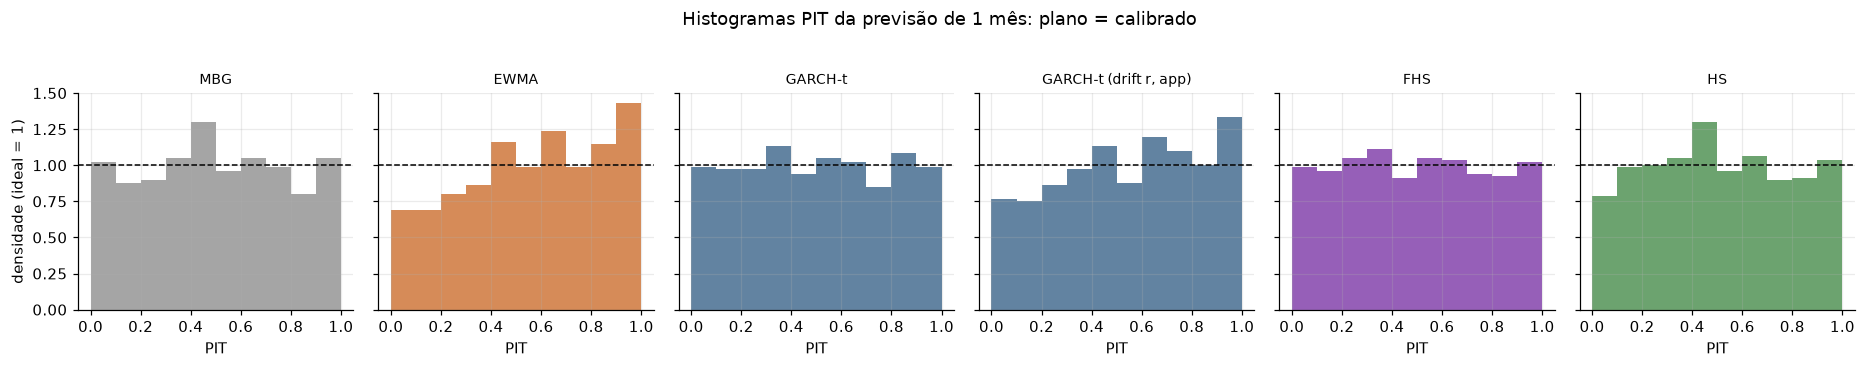

In [16]:
fig, ax = plt.subplots(1, len(MOD_ENT), figsize=(17, 3.2), sharey=True)
for a, m in zip(ax, MOD_ENT):
    a.hist(ENT[ENT.modelo == m].pit, bins=10, range=(0, 1), density=True, color=COR_MODELO.get(m.split(" ")[0], CINZA), alpha=0.7)
    a.axhline(1, color="k", ls="--", lw=1)
    a.set_title(m, fontsize=9); a.set_xlabel("PIT")
ax[0].set_ylabel("densidade (ideal = 1)")
plt.suptitle("Histogramas PIT da previsão de 1 mês: plano = calibrado", y=1.03); plt.tight_layout(); plt.show()

ordem = {}
for m, g in ENT.groupby("modelo"):
    for pp in PS_ORDEM:
        ordem[(m, f"p = {pp:.0%}")] = {
            "execução prevista": pp, "execução real": g[f"exec{pp}"].mean(),
            "p binomial": stats.binomtest(int(g[f"exec{pp}"].sum()), len(g), pp).pvalue,
            "desconto prometido": g[f"desc_mod{pp}"].mean(), "desconto real": g[f"desc_real{pp}"].mean(),
            "dp desconto real": g[f"desc_real{pp}"].std() / np.sqrt(len(g)),
            "preço-limite médio (% abaixo)": -(np.exp(g[f"L{pp}"]) - 1).mean(),
        }
ordem = pd.DataFrame(ordem).T.reindex(MOD_ENT, level=0)
display(ordem.style.format("{:.1%}").format("{:.3f}", subset=["p binomial"]))

**Como ler a tabela da ordem limitada.** Descontos em log-retorno (≈ %). "Desconto real" > 0 significa que a regra (ordem em $L_p$, com entrada forçada no fim) comprou, em média, **mais barato** do que comprar no dia $t$. "Desconto prometido" é o mesmo número calculado *dentro* da simulação. Um modelo bem calibrado tem execução real ≈ prevista e desconto real ≈ prometido (dentro de ~2 dp).

**O que observar.**

* **Calibração da distribuição de 1 mês.** MBG, GARCH-t, FHS e HS passam no teste PIT (KS com p > 0,3) e cobrem ~80% e ~90% dos resultados com os intervalos de 80% e 90%. A diferença está na **precisão**: GARCH-t e FHS têm o menor CRPS (0,0448 contra 0,0464 do MBG), ou seja, distribuições mais estreitas quando o mercado está calmo e mais largas quando está turbulento.
* **O drift importa em 1 mês, e o app usa o drift errado para essa pergunta.** O EWMA (drift zero) e o GARCH-t com drift neutro ao risco (o `simulate_price_paths` do app) são **rejeitados**: preveem $\mathbb P(\text{perda})$ de 47–50%, mas a frequência real foi 41,6%, porque as elétricas renderam bem acima da Selic no período. É a distinção $\mathbb P\times\mathbb Q$ do notebook original, agora **medida**: $\mathbb Q$ é a medida certa para **apreçar** a put, mas para informar ao usuário a chance real de perda é preciso simular sob $\mathbb P$. Com $\mathbb Q$ a estimativa fica conservadora.
* **Nenhum modelo prevê a direção.** O *Brier skill* é negativo para todos: dizer "a ação cai no próximo mês com 41% de chance" todo mês (a frequência histórica) é tão bom quanto qualquer modelo. Os modelos medem **dispersão e risco**, não *timing*.
* **Ordem limitada.** GARCH-t e FHS acertam a probabilidade de execução nos três níveis (por exemplo, 47% para 50% prometidos; o teste binomial não rejeita). MBG, HS e os modelos de drift errado executam **menos** do que prometem (o teste binomial os rejeita na maioria dos níveis). Uma explicação para o MBG: o $\sigma$ de 252 dias fica "velho" depois das crises e coloca o limite baixo demais (3,5% abaixo do preço, em média, contra 3,1% do GARCH-t).
* **O desconto médio da espera é negativo em todos os modelos** (≈ −1,2% com $p=50\%$): esperar com uma ordem limitada foi, em média, **pior** do que comprar já, porque as ações subiram no período. GARCH-t e FHS **previram** esse custo (≈ −1,1% prometido contra ≈ −1,2% realizado, dentro de 1 dp). Os modelos com drift zero prometiam desconto ≈ 0. Isso é o teorema da parada opcional: sem drift, nenhuma regra de espera melhora o preço esperado. **Conclusão sobre o preço de entrada:** o Monte Carlo informa corretamente a **probabilidade** de conseguir um preço melhor, mas não cria vantagem esperada. O ganho de quem é executado é compensado por quem perde a alta.

---
# Parte 6 — Puts reais da B3: os modelos acertam o prêmio?

No original, o Monte Carlo era validado contra Black–Scholes, e Black–Scholes era a "verdade". No mercado, a referência é o **preço negociado**. Agora testamos se o prêmio previsto pelos modelos (calibrados só com o histórico da ação) bate com o prêmio que o mercado cobrou.

**Dados.** Puts da COTAHIST ligadas à ação pelo ISIN, com filtros de liquidez: pelo menos 5 negócios no dia, prêmio ≥ R\$ 0,05, $K/S\in[0{,}80;\,1{,}10]$ e prazo entre 5 e 120 pregões. Preço de mercado = último negócio (`preult`); também guardamos a mínima e a máxima do dia.

**Premissas (e suas limitações).**
* As puts de ações na B3 são, em geral, **europeias**, então a fórmula de Black–Scholes para put se aplica.
* $q=0$: a B3 **ajusta o strike** das opções pelos dividendos/JCP, o que neutraliza o efeito do provento sobre a opção.
* $r$ = Selic contínua do dia; $\tau$ = pregões até o vencimento / 252.
* O último negócio da opção pode ter ocorrido horas antes do fechamento da ação (**assincronia**). Por isso, além do erro, medimos se o preço do modelo cai **dentro da faixa [mínima, máxima]** negociada no dia.

**Modelos de prêmio.**

| Modelo | Volatilidade usada em Black–Scholes |
|---|---|
| BS-MBG | $\hat\sigma$ dos últimos 252 dias (o que o notebook original faria) |
| BS-EWMA | $\sigma_{t+1}$ do EWMA |
| BS-GARCH | volatilidade média prevista pelo GARCH **até o vencimento**: $\bar\sigma^2=\sigma^2_\infty+\frac{1-\phi^n}{n(1-\phi)}(\sigma^2_{t+1}-\sigma^2_\infty)$, $\phi=\alpha+\beta$ |
| MC GARCH-t (app) | Monte Carlo neutro ao risco de `pricing/garch_montecarlo.py` (inclui a cauda $t$) — numa subamostra |
| IV de ontem (referência) | volatilidade implícita ATM do pregão anterior: o que um *trader* usaria; mostra o quanto da informação está no próprio mercado |

In [17]:
puts_raw = pd.read_csv(DADOS / "eletrico_put_2010_2026.csv", parse_dates=["data_pregao", "datven"])
isin_para_tk = acoes_raw.drop_duplicates("codneg").set_index("codisi").codneg
puts_raw = puts_raw[puts_raw.codisi.isin(isin_para_tk.index)].copy()
puts_raw["ticker"] = puts_raw.codisi.map(isin_para_tk)

# calendário de pregões (todas as datas da COTAHIST) para contar dias úteis até o vencimento
CAL = np.array(sorted(acoes_raw.data_pregao.unique()), dtype="datetime64[D]")
def pregoes_entre(d0, d1):
    d0, d1 = np.asarray(d0, dtype="datetime64[D]"), np.asarray(d1, dtype="datetime64[D]")
    n = np.searchsorted(CAL, d1, side="right") - np.searchsorted(CAL, d0, side="right")
    alem = d1 > CAL[-1]                                    # vencimentos depois do último dado
    n = np.where(alem, np.searchsorted(CAL, CAL[-1], side="right") - np.searchsorted(CAL, d0, side="right")
                 + np.busday_count(CAL[-1], d1), n)
    return n

def bs_put(S, K, r, sigma, tau):
    tau = np.maximum(tau, 1e-8); sigma = np.maximum(sigma, 1e-6)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return K * np.exp(-r * tau) * norm.cdf(-d2) - S * norm.cdf(-d1)

def bs_put_delta(S, K, r, sigma, tau):
    tau = np.maximum(tau, 1e-8); sigma = np.maximum(sigma, 1e-6)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return norm.cdf(d1) - 1.0

def vol_implicita(preco, S, K, r, tau, lo=0.01, hi=3.0, iters=70):
    """Bisseção vetorizada; NaN quando o preço está fora do intervalo de não arbitragem."""
    lo, hi = np.full(len(preco), lo), np.full(len(preco), hi)
    ok = (preco > bs_put(S, K, r, lo, tau)) & (preco < bs_put(S, K, r, hi, tau))
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        acima = bs_put(S, K, r, mid, tau) > preco
        hi = np.where(acima, mid, hi); lo = np.where(acima, lo, mid)
    return np.where(ok, 0.5 * (lo + hi), np.nan)

base = []
for tk, s in SERIES.items():
    P = PREV[tk]
    phi = (P.alpha + P.beta).clip(upper=0.9999)
    lr = P.omega / (1 - phi)
    base.append(pd.DataFrame({"ticker": tk, "S": s.S_bruto, "r_livre": s.r_livre, "sig_mbg": P.sig_mbg,
                              "sig_ewma": P.sig_ewma, "sig2_g": P.sig_g**2, "phi": phi, "sig2_lr": lr,
                              "mu_g": P.mu_g, "omega": P.omega, "alpha": P.alpha, "beta": P.beta, "nu_g": P.nu_g}))
base = pd.concat(base).rename_axis("data_pregao").reset_index()
OP = puts_raw.merge(base, on=["data_pregao", "ticker"], how="inner")
OP["du"] = pregoes_entre(OP.data_pregao.values, OP.datven.values)
OP["tau"] = OP.du / DU
OP["mny"] = OP.preexe / OP.S
OP = OP[(OP.totneg >= 5) & (OP.preult >= 0.05) & OP.mny.between(0.80, 1.10) & OP.du.between(5, 120)
        & OP.sig_mbg.notna()].copy()
n_ = OP.du.values.astype(float)
OP["sig_garch_prazo"] = np.sqrt(DU * (OP.sig2_lr + (1 - OP.phi**n_) / (n_ * (1 - OP.phi)) * (OP.sig2_g - OP.sig2_lr)))
OP["iv"] = vol_implicita(OP.preult.values, OP.S.values, OP.preexe.values, OP.r_livre.values, OP.tau.values)
OP = OP[OP.iv.notna()].copy()

# referência: IV ATM (mediana de |K/S-1|<5%, 10-60 pregões) do pregão ANTERIOR da mesma ação
atm = (OP[(OP.mny.sub(1).abs() < 0.05) & OP.du.between(10, 60)]
       .groupby(["ticker", "data_pregao"]).iv.median().rename("iv_atm").reset_index())
atm["iv_atm_ontem"] = atm.groupby("ticker").iv_atm.shift(1)
OP = OP.merge(atm[["ticker", "data_pregao", "iv_atm", "iv_atm_ontem"]], on=["ticker", "data_pregao"], how="left")

S_, K_, r_, tau_ = OP.S.values, OP.preexe.values, OP.r_livre.values, OP.tau.values
OP["BS-MBG"] = bs_put(S_, K_, r_, OP.sig_mbg.values * np.sqrt(DU), tau_)
OP["BS-EWMA"] = bs_put(S_, K_, r_, OP.sig_ewma.values * np.sqrt(DU), tau_)
OP["BS-GARCH"] = bs_put(S_, K_, r_, OP.sig_garch_prazo.values, tau_)
OP["IV de ontem"] = bs_put(S_, K_, r_, OP.iv_atm_ontem.values, tau_)
print(f"{len(OP):,} cotações de puts líquidas, {OP.codneg.nunique():,} séries, "
      f"{OP.data_pregao.min().date()} a {OP.data_pregao.max().date()}".replace(",", "."))
display(OP.groupby("ticker").agg(cotações=("codneg", "size"), séries=("codneg", "nunique"),
                                 primeiro=("data_pregao", "min"), IV_mediana=("iv", "median")))

69.444 cotações de puts líquidas. 5.590 séries. 2019-01-15 a 2026-10-16


,cotações,séries,primeiro,IV_mediana
ticker,,,,
CMIG4,16135,792,2019-01-15,0.2749
CPFE3,1300,429,2021-06-24,0.2372
CPLE3,1130,157,2025-09-04,0.2842
EGIE3,15513,1122,2019-01-23,0.2239
ENEV3,4444,578,2021-02-01,0.3410
EQTL3,14915,1537,2019-01-18,0.2801
TAEE11,16007,975,2019-01-28,0.2017


In [18]:
# Monte Carlo GARCH-t neutro ao risco (o método do app) numa subamostra de (ação, data)
g_op = np.random.default_rng(SEMENTE + 6)
grupos = OP.groupby(["ticker", "data_pregao"]).size().index.to_frame(index=False)
amostra = grupos.sample(n=min(250, len(grupos)), random_state=SEMENTE)
OP["MC GARCH-t (app)"] = np.nan
t0 = time.time()
for _, (tk, d) in amostra.iterrows():
    sel = (OP.ticker == tk) & (OP.data_pregao == d)
    linha = OP[sel].iloc[0]
    hmax = int(OP.loc[sel, "du"].max())
    X = simular_garch(0.0, linha.omega, linha.alpha, linha.beta, linha.nu_g, linha.sig2_g, hmax, 10_000, g_op)
    dias = np.arange(1, hmax + 1)
    X = X - np.log(np.mean(np.exp(X), axis=0))[None, :] + linha.r_livre * dias / DU   # E[S_k] = S e^{rk}
    for i in OP.index[sel]:
        k = int(OP.at[i, "du"]) - 1
        ST = OP.at[i, "S"] * np.exp(X[:, k])
        OP.at[i, "MC GARCH-t (app)"] = np.exp(-OP.at[i, "r_livre"] * OP.at[i, "tau"]) * np.maximum(OP.at[i, "preexe"] - ST, 0).mean()
print(f"MC GARCH-t: {sel.sum()} puts no último grupo; {OP['MC GARCH-t (app)'].notna().sum()} puts no total, {time.time() - t0:.0f} s")

MOD_OP = ["BS-MBG", "BS-EWMA", "BS-GARCH", "MC GARCH-t (app)", "IV de ontem"]
def metricas_preco(d, m):
    d = d[d[m].notna()]
    e = d[m] - d.preult
    return {"n": len(d), "viés (R$)": e.mean(), "MAE (R$)": e.abs().mean(), "RMSE (R$)": np.sqrt((e**2).mean()),
            "erro relativo mediano": (e / d.preult).median(),
            "|erro| relativo mediano": (e / d.preult).abs().median(),
            "dentro de [mín, máx] do dia": ((d[m] >= d.premin - 0.005) & (d[m] <= d.premax + 0.005)).mean()}
sub = OP[OP["MC GARCH-t (app)"].notna() & OP["IV de ontem"].notna()]
tab_op = pd.DataFrame({m: metricas_preco(OP, m) for m in MOD_OP}).T
tab_op_sub = pd.DataFrame({m: metricas_preco(sub, m) for m in MOD_OP}).T
fmt = {"n": "{:.0f}", "viés (R$)": "{:+.3f}", "MAE (R$)": "{:.3f}", "RMSE (R$)": "{:.3f}",
       "erro relativo mediano": "{:+.1%}", "|erro| relativo mediano": "{:.1%}", "dentro de [mín, máx] do dia": "{:.1%}"}
display(tab_op.style.format(fmt).set_caption("Todas as puts líquidas (MC só na subamostra)"))
display(tab_op_sub.style.format(fmt).set_caption("Mesma subamostra para todos os modelos (comparação justa com o MC)"))

MC GARCH-t: 13 puts no último grupo; 1915 puts no total, 3 s


,n,viés (R$),MAE (R$),RMSE (R$),erro relativo mediano,|erro| relativo mediano,"dentro de [mín, máx] do dia"
BS-MBG,69444,-0.064,0.110,0.175,-10.8%,17.6%,34.9%
BS-EWMA,69444,-0.063,0.122,0.175,-14.7%,22.1%,29.4%
BS-GARCH,69444,-0.037,0.106,0.165,-4.7%,17.4%,35.1%
MC GARCH-t (app),1915,-0.044,0.102,0.157,-6.2%,17.5%,33.7%
IV de ontem,68644,-0.012,0.065,0.105,-3.0%,10.1%,50.2%


,n,viés (R$),MAE (R$),RMSE (R$),erro relativo mediano,|erro| relativo mediano,"dentro de [mín, máx] do dia"
BS-MBG,1893,-0.058,0.116,0.183,-10.3%,19.3%,32.0%
BS-EWMA,1893,-0.060,0.116,0.173,-13.6%,21.6%,28.7%
BS-GARCH,1893,-0.030,0.101,0.155,-3.4%,17.5%,33.7%
MC GARCH-t (app),1893,-0.043,0.101,0.157,-6.0%,17.4%,33.9%
IV de ontem,1893,-0.016,0.065,0.101,-3.9%,10.8%,49.5%


,BS-MBG,BS-EWMA,BS-GARCH,MC GARCH-t (app),IV de ontem
faixa K/S,,,,,
"OTM profunda (0,80–0,90)",-72.9%,-63.4%,-65.0%,-48.3%,-46.3%
"OTM (0,90–0,97)",-28.9%,-34.8%,-19.8%,-21.5%,-14.4%
"ATM (0,97–1,03)",-6.6%,-11.0%,-0.3%,-3.4%,+0.5%
"ITM (1,03–1,10)",-1.5%,-2.0%,+0.7%,-0.0%,+1.0%


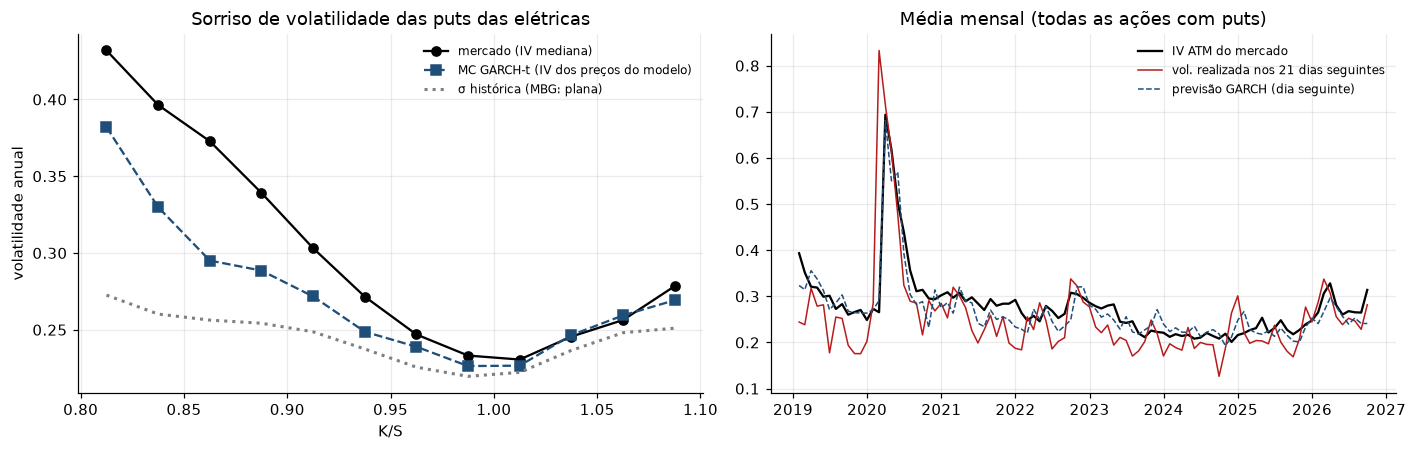

prêmio de risco de volatilidade (IV ATM − vol. realizada futura): mediana +2.9%, positivo em 69% dos dias
  previsão da vol. realizada de 21 dias por IV ATM: viés +2.4%, MAE 6.0%, correlação 0.59
  previsão da vol. realizada de 21 dias por GARCH : viés +1.5%, MAE 6.1%, correlação 0.54


In [19]:
OP["faixa K/S"] = pd.cut(OP.mny, [0.80, 0.90, 0.97, 1.03, 1.10], labels=["OTM profunda (0,80–0,90)", "OTM (0,90–0,97)", "ATM (0,97–1,03)", "ITM (1,03–1,10)"])
por_faixa = pd.DataFrame({m: OP[OP[m].notna()].assign(e=lambda d: (d[m] - d.preult) / d.preult)
                          .groupby("faixa K/S", observed=True).e.median() for m in MOD_OP})
display(por_faixa.style.format("{:+.1%}").set_caption("Erro relativo mediano (modelo − mercado)/mercado por moneyness"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
# sorriso: IV de mercado e IV implícita nos preços do MC GARCH-t, por moneyness
cortes = np.arange(0.80, 1.101, 0.025)
OP["bin"] = pd.cut(OP.mny, cortes)
sub = OP[OP["MC GARCH-t (app)"].notna()].copy()
sub["iv_mc"] = vol_implicita(sub["MC GARCH-t (app)"].values, sub.S.values, sub.preexe.values, sub.r_livre.values, sub.tau.values)
centro = [(c.left + c.right) / 2 for c in OP.bin.cat.categories]
ax[0].plot(centro, OP.groupby("bin", observed=False).iv.median().values, "o-", color="k", label="mercado (IV mediana)")
ax[0].plot(centro, sub.groupby("bin", observed=False).iv_mc.median().values, "s--", color=AZUL, label="MC GARCH-t (IV dos preços do modelo)")
ax[0].plot(centro, (OP.groupby("bin", observed=False).sig_mbg.median() * np.sqrt(DU)).values, ":", color=CINZA, lw=2, label="σ histórica (MBG: plana)")
ax[0].set_xlabel("K/S"); ax[0].set_ylabel("volatilidade anual"); ax[0].set_title("Sorriso de volatilidade das puts das elétricas"); ax[0].legend(fontsize=8)

# prêmio de risco de volatilidade: IV ATM vs volatilidade realizada nos 21 pregões seguintes
vr = []
for tk, s in SERIES.items():
    real21 = s.r.rolling(21).std().shift(-21) * np.sqrt(DU)
    vr.append(pd.DataFrame({"ticker": tk, "data_pregao": s.index, "vol_realizada_futura": real21.values,
                            "garch": PREV[tk].sig_g.values * np.sqrt(DU)}))
vr = pd.concat(vr).merge(atm[["ticker", "data_pregao", "iv_atm"]], on=["ticker", "data_pregao"]).dropna()
mens = vr.set_index("data_pregao").groupby(pd.Grouper(freq="ME"))[["iv_atm", "vol_realizada_futura", "garch"]].mean()
ax[1].plot(mens.index, mens.iv_atm, color="k", label="IV ATM do mercado")
ax[1].plot(mens.index, mens.vol_realizada_futura, color=VERMELHO, lw=1, label="vol. realizada nos 21 dias seguintes")
ax[1].plot(mens.index, mens.garch, color=AZUL, lw=1, ls="--", label="previsão GARCH (dia seguinte)")
ax[1].set_title("Média mensal (todas as ações com puts)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

vrp = vr.iv_atm - vr.vol_realizada_futura
print(f"prêmio de risco de volatilidade (IV ATM − vol. realizada futura): mediana {vrp.median():+.1%}, "
      f"positivo em {np.mean(vrp > 0):.0%} dos dias")
for nome, col in [("IV ATM", "iv_atm"), ("GARCH", "garch")]:
    e = vr[col] - vr.vol_realizada_futura
    print(f"  previsão da vol. realizada de 21 dias por {nome:6s}: viés {e.mean():+.1%}, MAE {e.abs().mean():.1%}, "
          f"correlação {np.corrcoef(vr[col], vr.vol_realizada_futura)[0, 1]:.2f}")

**O que observar.**

* **Os modelos calibrados só no histórico da ação subestimam o prêmio das puts.** O BS-MBG (o que o notebook original faria) erra em −11% na mediana e só cai dentro da faixa negociada no dia em ~35% das cotações. O melhor modelo histórico é o BS-GARCH, com a volatilidade média prevista até o vencimento (viés mediano de −5%). A referência de mercado (IV ATM de ontem) tem erro absoluto relativo mediano de ~10%, contra ~17% do BS-GARCH, e cai na faixa do dia em ~50% dos casos: **a informação mais valiosa sobre o preço da opção está no próprio mercado de opções.**
* **O erro está quase todo nas puts fora do dinheiro.** ATM e ITM, o BS-GARCH praticamente acerta (erro mediano ≈ 0). Nas OTM profundas ($K/S<0{,}90$), **todos** os modelos cobram de 48% a 73% a menos que o mercado. O sorriso mostra o motivo: o mercado precifica a put com $K/S\approx0{,}81$ a ~43% de volatilidade, contra ~23% no dinheiro. O Monte Carlo GARCH-t (caudas $t$ + volatilidade variável) **gera parte desse sorriso** (a curva azul se curva para cima), mas não todo. O resto é o **prêmio pelo risco de crash** que os compradores de proteção aceitam pagar.
* **Prêmio de risco de volatilidade.** A IV ATM ficou acima da volatilidade que de fato se realizou em ~70% dos dias (mediana de +2,9 p.p.). Como previsor da volatilidade futura, a IV é um pouco mais informativa que o GARCH (correlação 0,59 contra 0,54), mas é viesada para cima.
* **Para o app:** a comparação "prêmio de mercado × preço teórico" de `strategy/risk_analysis.py` (`price_diff_pct`) vai marcar quase toda put OTM como "cara" se o preço teórico usar volatilidade histórica. Isso é o *skew* do mercado, não necessariamente uma oportunidade. A Parte 7 mostra quem ganha com essa diferença na prática.

---
# Parte 7 — Hedge com dados reais

As Seções 4.6 e 5 do original mostraram, **por simulação**, que (i) a put protetora reduz VaR/ES a um custo em retorno esperado e (ii) o *delta hedge* elimina o risco direcional, deixando só uma aposta em volatilidade: $\text{P\&L}\approx\sum_k-\tfrac12\Gamma_kS_k^2\big[(\delta S_k/S_k)^2-\sigma_h^2\delta t\big]$. Agora repetimos os dois experimentos **com as puts que de fato foram negociadas** e com o caminho real da ação.

**Seleção das operações (sem olhar o futuro).** Para cada ação e cada vencimento: no pregão com prazo mais próximo de 21 dias úteis (entre 15 e 30), escolhemos a put líquida com $K/S$ mais próximo de 0,95 (entre 0,90 e 1,00), comprada/vendida pelo último negócio do dia. Mantemos até o vencimento. Ficam de fora as operações com desdobramento/bonificação no meio (o contrato muda de tamanho) e as que vencem depois do último dado.

**Contabilidade.**
* Ação: retorno **total** (proventos incluídos). Put: o payoff usa o strike **do vencimento**, já ajustado pela B3 por proventos.
* Put protetora: $R=\dfrac{S_0\,e^{\sum r^{\text{total}}}+(K_T-S_T)^+}{S_0+P_0}-1$.
* Delta hedge do vendedor (exatamente o algoritmo da Seção 5.1 do original): recebe $P_0$, mantém $\Delta^{\text{put}}_k<0$ ações (vendido em ação, via aluguel), caixa rende Selic diária, proventos da posição vendida são pagos, rebalanceia no fechamento de cada pregão. O $\Delta$ usa a **volatilidade implícita da entrada**, $\sigma_h=\mathrm{IV}_0$.

In [20]:
puts_raw["chave"] = puts_raw.codneg + "_" + puts_raw.datven.dt.strftime("%Y%m%d")
OP["chave"] = OP.codneg + "_" + OP.datven.dt.strftime("%Y%m%d")
strike_por_dia = puts_raw.set_index(["chave", "data_pregao"]).preexe.sort_index()
ULTIMO = min(s.index[-1] for s in SERIES.values())

cand = OP[OP.du.between(15, 30) & OP.mny.between(0.90, 1.00) & (OP.datven <= ULTIMO)].copy()
cand["dist_prazo"] = (cand.du - 21).abs()
cand["dist_mny"] = (cand.mny - 0.95).abs()
# um pregão de entrada por (ação, vencimento): o mais próximo de 21 du; nele, a put mais próxima de K/S = 0,95
dia = cand.sort_values(["dist_prazo", "data_pregao"]).groupby(["ticker", "datven"]).data_pregao.first().rename("dia_entrada")
cand = cand.merge(dia, left_on=["ticker", "datven"], right_index=True)
cand = cand[cand.data_pregao == cand.dia_entrada].sort_values("dist_mny").groupby(["ticker", "datven"]).head(1)
# vencimentos semanais/mensais sobrepostos: fica um por (ação, mês de vencimento), o de maior volume
cand["mes"] = cand.datven.dt.to_period("M")
ops = cand.sort_values("voltot", ascending=False).groupby(["ticker", "mes"]).head(1).sort_values(["ticker", "datven"])

g_h = np.random.default_rng(SEMENTE + 7)
resultados_hedge = []
for _, o in ops.iterrows():
    s = SERIES[o.ticker]
    t0_ = s.index.get_loc(o.data_pregao)
    caminho = s[(s.index > o.data_pregao) & (s.index <= o.datven)]
    if len(caminho) < 5 or caminho.split.any():
        continue
    S0, P0, K0, r0, tau0, sig_h = o.S, o.preult, o.preexe, o.r_livre, o.tau, o.iv
    K_dia = strike_por_dia.loc[o.chave]
    K_dia = K_dia.reindex(K_dia.index.union(caminho.index)).ffill().reindex(caminho.index).fillna(K0)
    K_T, S_T = K_dia.iloc[-1], caminho.S_bruto.iloc[-1]
    payoff = max(K_T - S_T, 0.0)
    fator_total = np.exp(caminho.r.sum())
    # --- delta hedge diário do vendedor (algoritmo da Seção 5.1 do original) ---
    tau_k = pregoes_entre(caminho.index.values, np.full(len(caminho), o.datven.to_datetime64())) / DU
    delta = bs_put_delta(S0, K0, r0, sig_h, tau0)
    caixa = P0 - delta * S0
    S_ant, pnl_aprox, n = S0, 0.0, len(caminho)
    r_ant, tau_ant, K_ant = r0, tau0, K0
    for k, (d, lin) in enumerate(caminho.iterrows()):
        S_k = lin.S_bruto
        gama = norm.pdf((np.log(S_ant / K_ant) + (r_ant + 0.5 * sig_h**2) * tau_ant) / (sig_h * np.sqrt(tau_ant))) / (S_ant * sig_h * np.sqrt(tau_ant))
        ret = (S_k + S_ant * (np.exp(lin.r_div) - 1)) / S_ant - 1           # retorno total do dia
        pnl_aprox += -0.5 * gama * S_ant**2 * (ret**2 - sig_h**2 / DU)
        caixa *= np.exp(r_ant / DU)                                           # 2. juros
        caixa += delta * S_ant * (np.exp(lin.r_div) - 1)                      # vendido em ação paga o provento
        novo = bs_put_delta(S_k, K_dia[d], lin.r_livre, sig_h, tau_k[k]) if k < n - 1 else (-1.0 if S_k < K_T else 0.0)
        caixa -= (novo - delta) * S_k                                         # 4. rebalanceia
        delta, S_ant, r_ant, tau_ant, K_ant = novo, S_k, lin.r_livre, max(tau_k[k], 1 / DU), K_dia[d]
    pnl_hedge = caixa + delta * S_T - payoff
    sig_real = np.sqrt(np.mean(caminho.r.values**2) * DU)
    # --- previsão na entrada (GARCH-t sob P e MBG), para a put protetora ---
    p = PREV[o.ticker].iloc[t0_]
    X = simular_garch(p.mu_g, p.omega, p.alpha, p.beta, p.nu_g, p.sig_g**2, n, 10_000, g_h)[:, -1]
    Xm = n * p.mu_mbg + np.sqrt(n) * p.sig_mbg * g_h.standard_normal(10_000)
    prev = {}
    for nome, Y in [("GARCH-t", X), ("MBG", Xm)]:
        R_acao_sim = np.exp(Y) - 1
        R_pp_sim = (S0 * np.exp(Y) + np.maximum(K0 - S0 * np.exp(Y), 0)) / (S0 + P0) - 1
        prev |= {f"VaR95 ação {nome}": -np.quantile(R_acao_sim, 0.05), f"VaR95 PP {nome}": -np.quantile(R_pp_sim, 0.05),
                 f"E[R] PP {nome}": R_pp_sim.mean(), f"E[R] ação {nome}": R_acao_sim.mean()}
    resultados_hedge.append(dict(
        ticker=o.ticker, entrada=o.data_pregao, vencimento=o.datven, du=o.du, K_S=o.mny, S0=S0, premio=P0,
        premio_pct=P0 / S0, iv=sig_h, sig_real=sig_real, garch_prazo=o.sig_garch_prazo, payoff=payoff,
        R_acao=fator_total - 1, R_pp=(S0 * fator_total + payoff) / (S0 + P0) - 1,
        pnl_vendido_sem_hedge=(P0 * np.exp(r0 * tau0) - payoff) / S0,
        pnl_vendido_hedge=pnl_hedge / S0, pnl_aprox=pnl_aprox / S0,
        pnl_teorico=np.exp(r0 * tau0) * (P0 - bs_put(S0, K0, r0, sig_real, tau0)) / S0, **prev))
HED = pd.DataFrame(resultados_hedge)
print(f"{len(HED)} operações reais ({HED.ticker.value_counts().to_dict()}), de {HED.entrada.min().date()} a {HED.vencimento.max().date()}")
print(f"prazo mediano {HED.du.median():.0f} pregões, K/S mediano {HED.K_S.median():.3f}, prêmio mediano {HED.premio_pct.median():.2%} do preço da ação")

481 operações reais ({'EQTL3': 90, 'TAEE11': 90, 'CMIG4': 89, 'EGIE3': 87, 'ENEV3': 64, 'CPFE3': 50, 'CPLE3': 11}), de 2019-01-16 a 2026-10-16
prazo mediano 21 pregões, K/S mediano 0.955, prêmio mediano 1.10% do preço da ação


## 7.1 Put protetora: a proteção funcionou e custou o que o modelo dizia?

,retorno médio,desvio-padrão,P(perda),pior caso,VaR 95%,ES 95%
só ação,1.51%,7.56%,43.04%,-38.20%,9.91%,14.13%
ação + put (real),1.06%,6.06%,50.94%,-8.96%,6.12%,6.95%
redução (put vs só ação),—,19.81%,—,—,38.28%,50.80%


,violações VaR95 ação,violações VaR95 put protetora,p Kupiec (put protetora),custo previsto da proteção (E[R] ação − E[R] PP),custo realizado (média R ação − R PP)
GARCH-t,4.78%,3.33%,0.074,0.38%,0.45%
MBG,5.41%,3.53%,0.120,0.34%,0.45%


payoff médio / prêmio médio das puts compradas: 0.70 (< 1: em média quem comprou a proteção pagou mais do que recebeu)


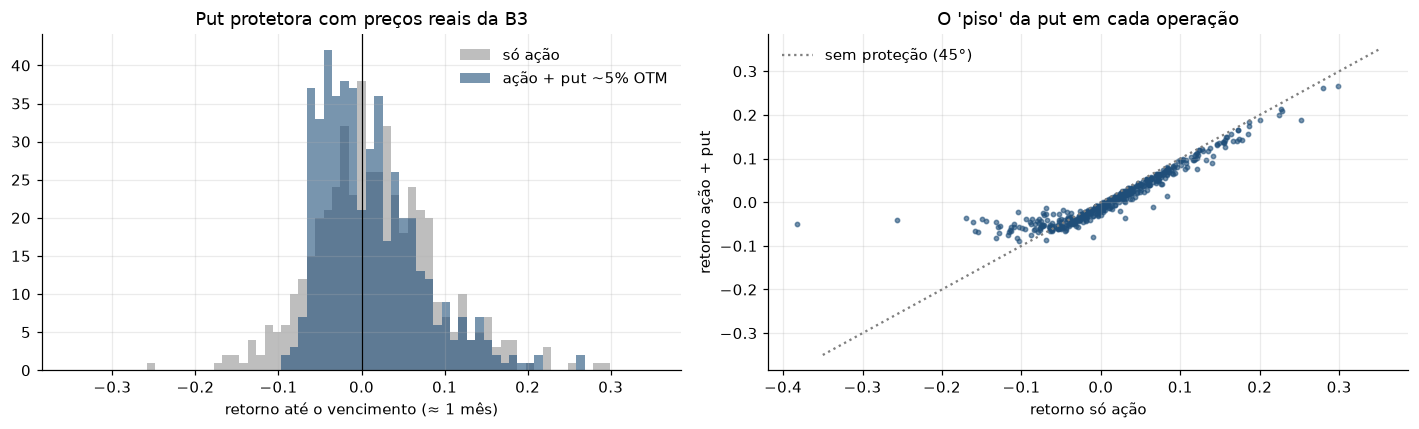

In [21]:
def resumo_ret(x):
    v95 = -np.quantile(x, 0.05)
    return {"retorno médio": x.mean(), "desvio-padrão": x.std(), "P(perda)": np.mean(x < 0),
            "pior caso": x.min(), "VaR 95%": v95, "ES 95%": -x[x <= -v95].mean()}
pp_tab = pd.DataFrame({"só ação": resumo_ret(HED.R_acao), "ação + put (real)": resumo_ret(HED.R_pp)}).T
pp_tab.loc["redução (put vs só ação)"] = 1 - pp_tab.loc["ação + put (real)"] / pp_tab.loc["só ação"]
pp_tab.loc["redução (put vs só ação)", ["retorno médio", "P(perda)", "pior caso"]] = np.nan
display(pp_tab.style.format("{:.2%}", na_rep="—"))

cob = {}
for nome in ["GARCH-t", "MBG"]:
    cob[nome] = {"violações VaR95 ação": np.mean(-HED.R_acao > HED[f"VaR95 ação {nome}"]),
                 "violações VaR95 put protetora": np.mean(-HED.R_pp > HED[f"VaR95 PP {nome}"]),
                 "p Kupiec (put protetora)": kupiec((-HED.R_pp > HED[f"VaR95 PP {nome}"]).values, 0.05)[1],
                 "custo previsto da proteção (E[R] ação − E[R] PP)": (HED[f"E[R] ação {nome}"] - HED[f"E[R] PP {nome}"]).mean(),
                 "custo realizado (média R ação − R PP)": (HED.R_acao - HED.R_pp).mean()}
display(pd.DataFrame(cob).T.style.format("{:.2%}").format("{:.3f}", subset=["p Kupiec (put protetora)"]))
print(f"payoff médio / prêmio médio das puts compradas: {HED.payoff.sum() / HED.premio.sum():.2f} "
      "(< 1: em média quem comprou a proteção pagou mais do que recebeu)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(-0.35, 0.35, 70)
ax[0].hist(HED.R_acao, bins=bins, alpha=0.5, color=CINZA, label="só ação")
ax[0].hist(HED.R_pp, bins=bins, alpha=0.6, color=AZUL, label="ação + put ~5% OTM")
ax[0].axvline(0, color="k", lw=0.8); ax[0].set_xlabel("retorno até o vencimento (≈ 1 mês)")
ax[0].set_title("Put protetora com preços reais da B3"); ax[0].legend()
ax[1].scatter(HED.R_acao, HED.R_pp, s=8, color=AZUL, alpha=0.6)
xx = np.linspace(-0.35, 0.35, 10); ax[1].plot(xx, xx, color=CINZA, ls=":", label="sem proteção (45°)")
ax[1].set_xlabel("retorno só ação"); ax[1].set_ylabel("retorno ação + put"); ax[1].set_title("O 'piso' da put em cada operação"); ax[1].legend()
plt.tight_layout(); plt.show()

**O que observar.**

* **A proteção funcionou como na Seção 4.6 do original.** Em 481 operações reais de ~1 mês, a put ~5% fora do dinheiro cortou o VaR 95% em ~38%, o ES 95% pela metade e o pior caso de −38% para −9%. No gráfico da direita, o "piso" aparece como a linha horizontal à esquerda.
* **O custo também apareceu:** o retorno médio caiu de 1,5% para 1,1% ao mês (≈ 0,45 p.p./mês, ou ~5% ao ano) e a probabilidade de perda **subiu** (43% → 51%), porque pagar o prêmio transforma pequenos ganhos em pequenas perdas. Em média, cada R\$ 1 de prêmio pago devolveu R\$ 0,70 de *payoff*. É o prêmio de risco de volatilidade da Parte 6, visto pelo lado do comprador.
* **Previsão na entrada.** O VaR 95% previsto pelo GARCH-t para a ação foi violado em 4,8% das operações, praticamente o alvo. Para a posição protegida houve 3,3% de violações (levemente conservador; p = 0,07). O custo previsto da proteção (0,38 p.p.) ficou um pouco abaixo do realizado (0,45 p.p.), outra vez porque o mercado cobra pela put mais do que o modelo acha que ela vale.

## 7.2 Delta hedge real: sobra mesmo só a aposta em volatilidade?

Três previsões da teoria (Seções 5.4, 5.6 e 5.8 do original), agora testáveis:

1. o *delta hedge* reduz drasticamente a dispersão do P&L do vendedor (contra o vendedor "parado");
2. o P&L que sobra é explicado por $\sum-\tfrac12\Gamma S^2[(\delta S/S)^2-\sigma_h^2\delta t]$ (o gráfico de 45°);
3. em média, $\mathbb E[\text{P\&L}]\approx e^{r\tau}[P(\sigma_h)-P(\sigma_{\text{real}})]$: o vendedor ganha quando a volatilidade implícita que cobrou supera a que se realizou.

,retorno médio,desvio-padrão,P(perda),pior caso,VaR 95%,ES 95%
vendido sem hedge,0.45%,2.92%,16.42%,-33.15%,4.43%,8.63%
vendido + delta hedge diário,0.27%,1.02%,28.48%,-7.26%,0.98%,2.45%
redução com hedge,—,65.07%,—,—,77.96%,71.59%


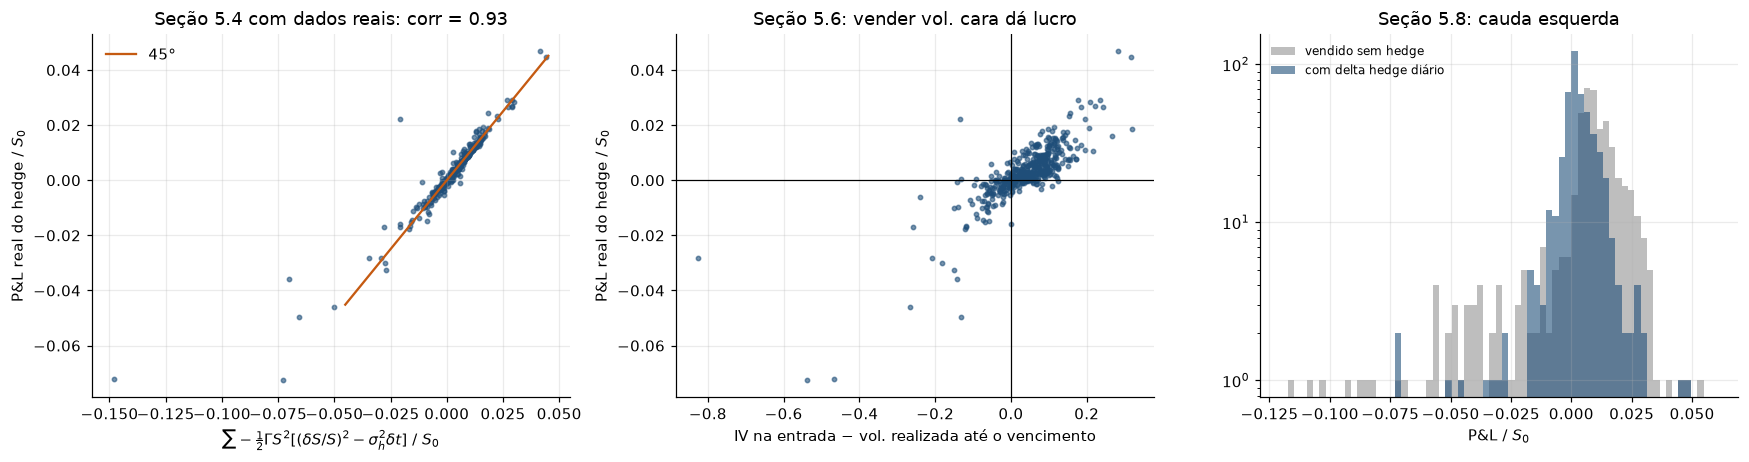

correlação P&L real × aproximação ½ΓS²[(δS/S)² − σ_h²δt]: 0.93
P&L médio do hedge: real +0.268% de S0  |  teoria e^(rτ)[P(σ_h) − P(σ_real)]: +0.271%
correlação P&L real × teoria por operação: 0.81
piores operações com hedge:


,ticker,entrada,vencimento,K_S,iv,sig_real,pnl_vendido_hedge,pnl_vendido_sem_hedge
311,EQTL3,2020-02-10,2020-03-16,0.9768,0.2411,0.7784,-0.0726,-0.2165
160,EGIE3,2020-02-14,2020-03-16,0.9669,0.2428,0.7110,-0.0720,-0.0874
245,ENEV3,2022-02-17,2022-03-18,0.9222,0.3875,0.5185,-0.0498,0.0116
401,TAEE11,2020-02-11,2020-03-16,0.9685,0.2195,0.4863,-0.0459,-0.1019
293,ENEV3,2026-02-19,2026-03-20,0.9589,0.4826,0.6256,-0.0360,0.0323


IV na entrada > vol. realizada em 75% das operações (IV mediana 26.3%, vol. realizada mediana 22.5%)


In [22]:
dh = pd.DataFrame({"vendido sem hedge": resumo_ret(HED.pnl_vendido_sem_hedge),
                   "vendido + delta hedge diário": resumo_ret(HED.pnl_vendido_hedge)}).T
dh.loc["redução com hedge"] = 1 - dh.loc["vendido + delta hedge diário"] / dh.loc["vendido sem hedge"]
dh.loc["redução com hedge", ["retorno médio", "P(perda)", "pior caso"]] = np.nan
display(dh.style.format("{:.2%}", na_rep="—").set_caption("P&L do vendedor da put em % do preço da ação"))

corr_aprox = np.corrcoef(HED.pnl_aprox, HED.pnl_vendido_hedge)[0, 1]
corr_teo = np.corrcoef(HED.pnl_teorico, HED.pnl_vendido_hedge)[0, 1]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
lim = np.quantile(np.abs(HED[["pnl_vendido_hedge", "pnl_aprox"]].values), 0.99)
ax[0].scatter(HED.pnl_aprox, HED.pnl_vendido_hedge, s=8, alpha=0.6, color=AZUL)
ax[0].plot([-lim, lim], [-lim, lim], color=LARANJA, label="45°")
ax[0].set_xlabel("$\\sum -\\frac{1}{2}\\Gamma S^2[(\\delta S/S)^2-\\sigma_h^2\\delta t]$ / $S_0$")
ax[0].set_ylabel("P&L real do hedge / $S_0$"); ax[0].set_title(f"Seção 5.4 com dados reais: corr = {corr_aprox:.2f}"); ax[0].legend()
ax[1].scatter(HED.iv - HED.sig_real, HED.pnl_vendido_hedge, s=8, alpha=0.6, color=AZUL)
ax[1].axhline(0, color="k", lw=0.8); ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("IV na entrada − vol. realizada até o vencimento"); ax[1].set_ylabel("P&L real do hedge / $S_0$")
ax[1].set_title("Seção 5.6: vender vol. cara dá lucro")
bins = np.linspace(-0.12, 0.06, 70)
ax[2].hist(HED.pnl_vendido_sem_hedge, bins=bins, alpha=0.5, color=CINZA, label="vendido sem hedge")
ax[2].hist(HED.pnl_vendido_hedge, bins=bins, alpha=0.6, color=AZUL, label="com delta hedge diário")
ax[2].set_yscale("log"); ax[2].set_xlabel("P&L / $S_0$"); ax[2].set_title("Seção 5.8: cauda esquerda"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"correlação P&L real × aproximação ½ΓS²[(δS/S)² − σ_h²δt]: {corr_aprox:.2f}")
print(f"P&L médio do hedge: real {HED.pnl_vendido_hedge.mean():+.3%} de S0  |  teoria e^(rτ)[P(σ_h) − P(σ_real)]: {HED.pnl_teorico.mean():+.3%}")
print(f"correlação P&L real × teoria por operação: {corr_teo:.2f}")
print("piores operações com hedge:")
display(HED.nsmallest(5, "pnl_vendido_hedge")[["ticker", "entrada", "vencimento", "K_S", "iv", "sig_real", "pnl_vendido_hedge", "pnl_vendido_sem_hedge"]])
print(f"IV na entrada > vol. realizada em {np.mean(HED.iv > HED.sig_real):.0%} das operações "
      f"(IV mediana {HED.iv.median():.1%}, vol. realizada mediana {HED.sig_real.median():.1%})")

**O que observar.**

* **A previsão 1 se confirma, com a ressalva do mundo real.** O *delta hedge* diário reduziu o desvio-padrão do P&L do vendedor em ~65% e o ES 95% em ~72%; o pior caso foi de −33% para −7% de $S_0$. Na simulação de Black–Scholes (Seção 5.8 do original) a redução do ES era de ~98%. A diferença é o que o mundo real acrescenta: **saltos** (as piores operações com hedge, listadas acima, são as que venceram em março de 2020, na Covid, e duas da ENEV3 com volatilidade realizada muito acima da implícita, como no teste de estresse da Seção 5.9), volatilidade que muda no caminho e rebalanceamento só no fechamento.
* **A previsão 2 se confirma.** O P&L real do hedge e a fórmula $\sum-\tfrac12\Gamma S^2[(\delta S/S)^2-\sigma_h^2\delta t]$, calculada no caminho real, têm correlação de ~0,93: o gráfico de 45° da Seção 5.4 **sobrevive aos dados reais**. O que sobra do hedge é, de fato, uma aposta em volatilidade ponderada pelo gama.
* **A previsão 3 se confirma.** O P&L médio real (+0,27% de $S_0$ por operação de ~1 mês) coincide com a previsão $e^{r\tau}[P(\sigma_h)-P(\sigma_{\text{real}})]$ (+0,27%), com correlação de ~0,8 operação a operação. Como a IV de entrada superou a volatilidade realizada em ~75% das operações, **quem vendeu puts das elétricas e fez o hedge ganhou o prêmio de volatilidade**. É o espelho do custo pago pelo comprador da put protetora em 7.1.
* **Fora do modelo:** custos de corretagem e emolumentos, *spread* compra/venda (a COTAHIST tem os campos `PREOFC`/`PREOFV` de melhor oferta, ainda não lidos pelo `cotahist_provider`) e o aluguel (BTC) da ação vendida. A Seção 5.7 do original mostra que o custo cresce com a frequência de rebalanceamento; medir quanto desse ganho sobra depois dos custos é o próximo teste natural.

---
# Parte 8 — Síntese: quais modelos funcionam no mercado brasileiro?

A tabela abaixo é **gerada a partir dos resultados** das Partes 4–6 (ela se atualiza sozinha se os dados mudarem). Para cada pergunta, o valor-alvo de um modelo correto aparece no nome da coluna.

In [23]:
mapa10 = {"MBG": "MBG (√10)", "EWMA": "EWMA (√10)", "GARCH-t": "GARCH-t (MC)", "FHS": "FHS (MC)", "HS": "HS (10d)"}
mapa_op = {"MBG": "BS-MBG", "EWMA": "BS-EWMA", "GARCH-t": "BS-GARCH"}
z2 = tab_bt[tab_bt.nivel == "ES 97,5%"].pivot(index="ticker", columns="modelo", values="z2")
sintese = pd.DataFrame({
    "VaR 99% 1d: violações (alvo 1%)": resumo_var[("VaR 99%", "taxa de violação")],
    "VaR 99% 1d: Kupiec ok (de 7)": resumo_var[("VaR 99%", "passa Kupiec (de 7)")],
    "VaR 99% 1d: cobertura cond. ok (de 7)": resumo_var[("VaR 99%", "passa cobertura cond.")],
    "Basileia: % janelas vermelhas (alvo 0)": semaforo["vermelho"] / 100,
    "ES 97,5%: Z2 médio (alvo 0)": z2.mean(),
    "perda FZ0 média (menor melhor)": fz_tab.loc["média"],
    "VaR 99% 10d: violações (alvo 1%)": pd.Series({m: res10.loc[mapa10[m], "taxa 99%"] for m in MODELOS}),
    "1 mês: p KS do PIT (>0,05 ok)": tab_ent["p KS (PIT uniforme)"],
    "1 mês: CRPS (menor melhor)": tab_ent["CRPS médio"],
    "ordem limitada p=50%: execução (alvo 50%)": ordem.xs("p = 50%", level=1)["execução real"],
    "puts: |erro| relativo mediano": pd.Series({m: tab_op.loc[mapa_op[m], "|erro| relativo mediano"] if m in mapa_op else np.nan for m in MODELOS}),
}).reindex(MODELOS)
sintese = sintese.rename(index={"MBG": "MBG (notebook original)", "GARCH-t": "GARCH-t (app)"})
pct = [c for c in sintese.columns if "violações" in c or "janelas" in c or "execução" in c or "erro" in c]
display(sintese.T.style.format("{:.3f}", na_rep="—").format("{:.2%}", subset=pd.IndexSlice[pct, :], na_rep="—")
        .format("{:.0f}", subset=pd.IndexSlice[[c for c in sintese.columns if "(de 7)" in c], :])
        .format("{:.4f}", subset=pd.IndexSlice[["1 mês: CRPS (menor melhor)"], :]))

print("Referências que não são 'modelos de risco' mas entram na conclusão:")
print(f"  • GARCH-t com drift neutro ao risco (como o app): p KS do PIT = {tab_ent.loc['GARCH-t (drift r, app)', 'p KS (PIT uniforme)']:.3f}, "
      f"P(perda) prevista {tab_ent.loc['GARCH-t (drift r, app)', 'P(perda) prevista']:.1%} vs real {tab_ent.loc['GARCH-t (drift r, app)', 'frequência real de perda']:.1%}")
print(f"  • puts: MC GARCH-t |erro| relativo mediano {tab_op.loc['MC GARCH-t (app)', '|erro| relativo mediano']:.1%}; "
      f"IV de ontem {tab_op.loc['IV de ontem', '|erro| relativo mediano']:.1%}")
print(f"  • put protetora real: ES 95% de {pp_tab.loc['só ação', 'ES 95%']:.1%} para {pp_tab.loc['ação + put (real)', 'ES 95%']:.1%}, "
      f"custo médio {cob['GARCH-t']['custo realizado (média R ação − R PP)']:.2%} por mês")
print(f"  • delta hedge real: ES 95% do vendedor de {dh.loc['vendido sem hedge', 'ES 95%']:.1%} para {dh.loc['vendido + delta hedge diário', 'ES 95%']:.1%} de S0; "
      f"P&L médio {HED.pnl_vendido_hedge.mean():+.2%} vs teoria {HED.pnl_teorico.mean():+.2%}")

,MBG (notebook original),EWMA,GARCH-t (app),HS,FHS
VaR 99% 1d: violações (alvo 1%),1.65%,1.45%,0.95%,1.40%,1.11%
VaR 99% 1d: Kupiec ok (de 7),1,5,7,5,6
VaR 99% 1d: cobertura cond. ok (de 7),0,5,7,3,6
Basileia: % janelas vermelhas (alvo 0),9.88%,0.00%,0.00%,6.88%,0.00%
"ES 97,5%: Z2 médio (alvo 0)",-0.357,-0.173,0.068,-0.200,-0.023
perda FZ0 média (menor melhor),-3.008,-3.185,-3.187,-2.998,-3.182
VaR 99% 10d: violações (alvo 1%),1.11%,0.89%,0.74%,1.33%,0.67%
"1 mês: p KS do PIT (>0,05 ok)",0.814,0.000,0.948,0.346,0.932
1 mês: CRPS (menor melhor),0.0464,0.0457,0.0448,0.0455,0.0448
ordem limitada p=50%: execução (alvo 50%),42.86%,39.56%,47.41%,44.11%,47.10%


Referências que não são 'modelos de risco' mas entram na conclusão:
  • GARCH-t com drift neutro ao risco (como o app): p KS do PIT = 0.001, P(perda) prevista 47.2% vs real 41.6%
  • puts: MC GARCH-t |erro| relativo mediano 17.5%; IV de ontem 10.1%
  • put protetora real: ES 95% de 14.1% para 7.0%, custo médio 0.45% por mês
  • delta hedge real: ES 95% do vendedor de 8.6% para 2.5% de S0; P&L médio +0.27% vs teoria +0.27%


## Respostas às perguntas do estudo

**1. Os modelos propostos preveem corretamente o risco nas elétricas brasileiras?**

* **O MBG com $\sigma$ constante (o modelo do notebook original) não serve para o risco diário de cauda.** Ele viola o VaR 99% ~65% mais do que promete, com violações em sequência (rejeitado na cobertura condicional nas 7 ações), e subestima o ES. No horizonte de 10 dias ele se salva, porque a agregação aproxima a normal.
* **O GARCH(1,1)-t, que é o modelo do app, passa em todos os testes de VaR 99% de 1 dia nas 7 ações**, tem o melhor escore conjunto VaR+ES (FZ0) e é significativamente melhor que o MBG em 4 ações. A FHS é uma alternativa equivalente. O EWMA reage bem, mas a cauda normal ainda falha a 99%.

**2. A distribuição prevista do preço serve para decidir a entrada?**

* **Sim, para probabilidades; não, para direção.** As distribuições de 1 mês do GARCH-t/FHS são calibradas (PIT uniforme) e as mais precisas (CRPS). A probabilidade de uma ordem limitada ser executada é prevista corretamente. Mas nenhum modelo prevê se a ação sobe ou cai melhor do que a frequência histórica, e esperar com ordem limitada não melhorou o preço médio de entrada.
* **O drift importa:** com drift neutro ao risco (como em `simulate_price_paths`), a $\mathbb P(\text{perda})$ mostrada ao usuário fica viesada para cima (47% previsto contra 42% real).

**3. Os modelos acertam o preço de entrada na put e o resultado do hedge?**

* **Prêmio:** modelos calibrados só com o histórico da ação acertam as puts no dinheiro (BS-GARCH, erro mediano ≈ 0), mas cobram muito menos que o mercado pelas OTM: o mercado tem *skew* e prêmio de risco de volatilidade. Para apreçar, a volatilidade implícita de mercado é a melhor informação disponível.
* **Hedge:** a teoria do notebook original (put protetora corta a cauda com custo em retorno; o *delta hedge* deixa só a aposta em volatilidade $\tfrac12\Gamma S^2(\sigma_r^2-\sigma_h^2)$; $\mathbb E[\text{P\&L}]\approx e^{r\tau}[P(\sigma_h)-P(\sigma_r)]$) **se confirmou com as puts reais negociadas na B3**.

## Recomendações para a dissertação e para o app

1. Medir risco (VaR/ES) com **GARCH-t ou FHS**; manter o MBG apenas como referência didática e mostrar o backtest que o reprova.
2. Separar as medidas no app: $\mathbb Q$ (drift $r$) para **preço** da put; $\mathbb P$ (drift estimado, ou ao menos as duas versões lado a lado) para **probabilidade de perda** e risco mostrados ao usuário.
3. Para o preço teórico da put, usar a volatilidade implícita (com *skew*) quando houver mercado de opções. A volatilidade histórica/GARCH serve como sinal de "cara/barata", lembrando que o *skew* é estrutural.
4. Reportar sempre os testes (Kupiec, Christoffersen, $Z_2$, PIT), não só o número do VaR.

## Limitações (para a seção de método)

* **Proventos:** fatores de desdobramento e de dividendos vêm do Yahoo (datas conferidas na B3). Erros residuais de data em dividendos pequenos são possíveis.
* **Opções:** último negócio (`preult`) em vez de bid/ask; assincronia com o fechamento da ação; liquidez concentrada em CMIG4, EGIE3, EQTL3 e TAEE11 (CPLE3 só tem puts líquidas a partir de 2025); custos de transação e aluguel não incluídos.
* **Testes:** as 7 ações são do mesmo setor e caem juntas, então os testes "conjuntos" não são independentes entre ações. Há vários testes simultâneos, e alguns p-valores baixos são esperados por acaso.
* **Período:** 2019–2026, com um único grande evento de cauda (Covid). Os resultados de cauda dependem fortemente dele.

## Extensões naturais

* Ler `PREOFC`/`PREOFV` da COTAHIST (melhores ofertas) e refazer a Parte 6 contra o *mid* e a Parte 7 com custo de *spread*.
* Testar o Heston, ou um GARCH assimétrico (GJR/EGARCH), para capturar o *skew* das puts.
* Backtest do delta hedge com custos (Seção 5.7 do original) e frequência ótima de rebalanceamento com dados reais.
* Usar a carteira de ações elétricas (correlação via Cholesky, Seção 4.5 do original) e testar o VaR da carteira.